# Does seeing the agent's plan make human feedback more useful?
### A first test with Q-learning in a 5×5 gridworld

**Pranto Bosu** · October 2026 · repository: [github.com/bosu0077/explanations-human-feedback-rl](https://github.com/bosu0077/explanations-human-feedback-rl)

**Question.** When a person trains a reinforcement-learning (RL) agent by pressing *good* or *bad*, does an explanation of the agent's behaviour — here, arrows that show what the agent currently plans to do in every cell — make the person's feedback more useful?

| Part | What is done | Main output |
|---|---|---|
| 1 | Tabular Q-learning (Sutton & Barto, 2018, Ch. 6) in a 5×5 gridworld, checked against the book's Cliff Walking example | learning curves |
| 2 | A simulated trainer: +1 for a correct move, −1 for a wrong one — but wrong 10–30 % of the time, and sometimes silent | how much slower the agent learns as feedback gets worse |
| 3 | A human pilot: 3–4 people press good/bad, once seeing only the agent and once seeing the agent plus its policy arrows | feedback needed, feedback correct, learning speed |
| 4 | Next step: how many people a real study would need | power curves |

> **Status of the human pilot.** The app (`pilot/pilot_app.py`), the protocol and the analysis are ready, but **no human data has been collected yet**. Until real logs are placed in `pilot/data/`, Part 3 runs the *same* analysis on **simulated participants**, only to check that the pipeline works. Those figures carry a red banner — *PIPELINE CHECK — simulated participants, not human data* — and are not results.

The notebook runs top to bottom in a few minutes on a laptop (set the environment variable `NB_FAST=1` for a quick smoke test). All code lives in `src/hitl_gridworld.py`; its sections are embedded below so the notebook is self-contained.

## 0. Setup

In [1]:
# ---- from src/hitl_gridworld.py, section [imports] ----
import csv
import json
import re
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.ticker
import matplotlib.pyplot as plt
from cycler import cycler
from matplotlib.colors import LinearSegmentedColormap, Normalize, to_rgba
from matplotlib.patches import Circle, FancyArrowPatch, Rectangle

__version__ = "1.0.0"

In [2]:
# ---- settings used by the whole notebook ------------------------------------------
import os
from IPython.display import Image, Markdown, display

FAST = os.environ.get("NB_FAST", "0") == "1"       # True: quick smoke test with fewer runs
N_SEEDS = 12 if FAST else 50                        # independent runs per condition
MAX_STEPS = 4000                                    # step budget per run in Part 2
ROOT = Path.cwd()
FIG, RES = ROOT / "figures", ROOT / "results"
PILOT_DATA = ROOT / "pilot" / "data"                # real pilot logs (pilot/pilot_app.py)
PIPELINE_CHECK = ROOT / "pilot" / "pipeline_check"  # simulated participants (pipeline test only)
for d in (FIG, RES):
    d.mkdir(parents=True, exist_ok=True)
T_START = time.time()
print(f"FAST={FAST} | runs per condition: {N_SEEDS} | numpy {np.__version__}, "
      f"matplotlib {matplotlib.__version__}, pandas {pd.__version__}")

FAST=False | runs per condition: 50 | numpy 2.5.3, matplotlib 3.11.2, pandas 3.0.5


## Part 1 — Q-learning in a 5×5 gridworld (Sutton & Barto, Ch. 6)

**Temporal-difference control.** Chapter 6 of Sutton & Barto (2018) learns action values $Q(s,a)$ from experience and updates them after every step using the *TD error*: the gap between the current estimate and a one-step, bootstrapped target. **Q-learning** (Sec. 6.5, Eq. 6.8) puts the best next action into the target,

$$Q(S_t,A_t) \leftarrow Q(S_t,A_t) + \alpha\big[R_{t+1} + \gamma \max_a Q(S_{t+1},a) - Q(S_t,A_t)\big],$$

so it learns the greedy policy while it *behaves* ε-greedily — it is **off-policy**. **Sarsa** (Sec. 6.4, Eq. 6.7) uses the action it will actually take next, $Q(S_{t+1},A_{t+1})$, so it learns the value of the ε-greedy policy it follows (**on-policy**). The book's Cliff Walking example (Example 6.6) shows the difference; it is reproduced below as a check on the code.

**The task.** The agent starts bottom-left and must reach the goal top-right. Walls block moves (bumping into one wastes a step); stepping into lava ends the episode. The shortest route is 8 moves along the bottom row and up the right column; going up the left column leads to a 12-move detour.

| | setting |
|---|---|
| rewards | +1 goal, −1 lava, −0.01 for every other step; episodes are cut off after 50 steps |
| agent | Q-learning, α = 0.5, γ = 0.95, ε = 0.1, Q₀ = 0, random tie-breaking |
| *learned* | the greedy policy from the start follows a shortest path (8 moves) |
| *policy accuracy* | share of the 17 non-terminal cells whose greedy action is a shortest-path move |

In [3]:
# ---- from src/hitl_gridworld.py, section [env] ----
# Actions as (row, col) moves. Row 0 is the TOP row of the grid.
ACTIONS = ((-1, 0), (0, 1), (1, 0), (0, -1))
ACTION_NAMES = ("up", "right", "down", "left")
N_ACTIONS = len(ACTIONS)

FREE, WALL, GOAL, LAVA = 0, 1, 2, 3

LAYOUTS = {
    # Main 5x5 map.  S = start, G = goal, # = wall, L = lava, . = free.
    # Shortest route (8 moves): along the bottom row, then up the right column.
    # Going up the left column leads to a 12-move detour; lava sits in the middle.
    "A": ["...#G",
          ".#.#.",
          ".#...",
          ".#L#.",
          "S...."],
    # Practice map for the pilot (no walls, no lava).
    "practice": ["....G",
                 ".....",
                 ".....",
                 ".....",
                 "S...."],
    # Sutton & Barto (2018) Example 6.6, Cliff Walking: 4 x 12, L = the cliff.
    "cliff": ["............",
              "............",
              "............",
              "SLLLLLLLLLLG"],
}
# Mirror image of map A, used for the second pilot session so that a participant
# cannot simply reuse what they memorised about the first map.
LAYOUTS["B"] = [row[::-1] for row in LAYOUTS["A"]]


class GridWorld:
    """Deterministic gridworld in the style of Sutton & Barto (2018), Ch. 6.

    * Moving off the grid or into a wall leaves the agent where it is (a "bump").
    * Entering the goal ends the episode with `goal_reward`.
    * Entering lava gives `lava_reward` and either ends the episode (default) or,
      with `lava_resets=True`, sends the agent back to the start (Cliff Walking).
    * Every other move gives `step_reward`.
    * Episodes are cut off (truncated, not terminated) after `max_episode_steps`.
    """

    def __init__(self, layout="A", step_reward=-0.01, goal_reward=1.0, lava_reward=-1.0,
                 lava_resets=False, max_episode_steps=50):
        self.name = layout if isinstance(layout, str) else "custom"
        rows = LAYOUTS[layout] if isinstance(layout, str) else list(layout)
        self.layout = [str(r) for r in rows]
        self.H, self.W = len(self.layout), len(self.layout[0])
        if any(len(r) != self.W for r in self.layout):
            raise ValueError("all rows of a layout must have the same length")
        self.n_states, self.n_actions = self.H * self.W, N_ACTIONS
        codes = {".": FREE, "S": FREE, "#": WALL, "G": GOAL, "L": LAVA}
        self.cell_type = np.full(self.n_states, FREE, dtype=int)
        starts = []
        for r, row in enumerate(self.layout):
            for c, ch in enumerate(row):
                if ch not in codes:
                    raise ValueError(f"unknown cell {ch!r} at ({r}, {c})")
                self.cell_type[r * self.W + c] = codes[ch]
                if ch == "S":
                    starts.append(r * self.W + c)
        if len(starts) != 1:
            raise ValueError("a layout needs exactly one start cell 'S'")
        if not np.any(self.cell_type == GOAL):
            raise ValueError("a layout needs at least one goal cell 'G'")
        self.start = starts[0]
        self.step_reward, self.goal_reward, self.lava_reward = step_reward, goal_reward, lava_reward
        self.lava_resets = lava_resets
        self.max_episode_steps = max_episode_steps
        # T[s, a] = cell reached from cell s with action a (before any lava handling).
        self.T = np.empty((self.n_states, N_ACTIONS), dtype=int)
        for s in range(self.n_states):
            r, c = divmod(s, self.W)
            for a, (dr, dc) in enumerate(ACTIONS):
                nr, nc = r + dr, c + dc
                inside = 0 <= nr < self.H and 0 <= nc < self.W
                blocked = (not inside) or self.cell_type[nr * self.W + nc] == WALL
                self.T[s, a] = s if blocked else nr * self.W + nc
        self._T = self.T.tolist()          # plain lists: faster single lookups
        self._type = self.cell_type.tolist()
        self.reset()

    def rc(self, s):
        """(row, col) of state index s."""
        return divmod(int(s), self.W)

    def reset(self):
        self.s, self.t = self.start, 0
        return self.s

    def step(self, a):
        """Take action a. Returns (next_state, reward, terminated, truncated)."""
        s2 = self._T[self.s][a]
        kind = self._type[s2]
        terminated = False
        if kind == GOAL:
            reward, terminated = self.goal_reward, True
        elif kind == LAVA:
            reward = self.lava_reward
            if self.lava_resets:
                s2 = self.start
            else:
                terminated = True
        else:
            reward = self.step_reward
        self.t += 1
        truncated = (not terminated and self.max_episode_steps is not None
                     and self.t >= self.max_episode_steps)
        self.s = s2
        return s2, reward, terminated, truncated

    def __repr__(self):
        return f"GridWorld({self.name!r}, {self.H}x{self.W})"

The **oracle** below knows the shortest path from every cell. It is used to score the agent (policy accuracy, *learned*), to drive the simulated trainer in Part 2, and to score human key presses in Part 3.

In [4]:
# ---- from src/hitl_gridworld.py, section [oracle] ----
class Oracle:
    """Shortest-path 'ground truth', used to score actions and feedback.

    dist[s]        number of moves from s to the goal (walls and lava are impassable)
    optimal[s, a]  True if action a moves one step closer to the goal
    states         non-terminal cells that can reach the goal (used for policy accuracy)
    route          non-terminal cells on a shortest path from the start (the cells the
                   'learned' criterion depends on)
    """

    def __init__(self, env):
        n = env.n_states
        passable = (env.cell_type != WALL) & (env.cell_type != LAVA)
        dist = np.full(n, np.inf)
        frontier = [int(g) for g in np.flatnonzero(env.cell_type == GOAL)]
        for g in frontier:
            dist[g] = 0.0
        while frontier:                       # breadth-first search outward from the goal
            nxt = []
            for s in frontier:
                for a in range(N_ACTIONS):
                    p = int(env.T[s, a])      # grid moves are reversible
                    if p != s and passable[p] and np.isinf(dist[p]):
                        dist[p] = dist[s] + 1
                        nxt.append(p)
            frontier = nxt
        self.dist = dist
        self.optimal = np.zeros((n, N_ACTIONS), dtype=bool)
        states = []
        for s in range(n):
            if env.cell_type[s] == FREE and np.isfinite(dist[s]):
                states.append(s)
                for a in range(N_ACTIONS):
                    p = int(env.T[s, a])
                    if p != s and passable[p] and dist[p] == dist[s] - 1:
                        self.optimal[s, a] = True
        self.states = np.array(states, dtype=int)
        self._opt = self.optimal.tolist()
        self.start_dist = int(dist[env.start]) if np.isfinite(dist[env.start]) else None
        # Cells on some shortest path from the start: follow optimal moves forward.
        route, frontier = set(), [env.start] if self.start_dist is not None else []
        while frontier:
            nxt = []
            for s in frontier:
                if s in route or env.cell_type[s] == GOAL:
                    continue
                route.add(s)
                nxt.extend(int(env.T[s, a]) for a in np.flatnonzero(self.optimal[s]))
            frontier = nxt
        self.route = np.array(sorted(route), dtype=int)


def strict_greedy(Q):
    """Greedy action in every state, or -1 where the best value is tied (no preference yet)."""
    best = Q.max(axis=1, keepdims=True)
    tied = (Q == best).sum(axis=1) > 1
    greedy = Q.argmax(axis=1)
    greedy[tied] = -1
    return greedy


def policy_accuracy(Q, oracle, states=None):
    """Fraction of cells (default: all non-terminal cells) whose greedy action is a
    shortest-path action."""
    states = oracle.states if states is None else states
    g = strict_greedy(Q)[states]
    ok = g >= 0
    ok[ok] = oracle.optimal[states[ok], g[ok]]
    return float(ok.mean())


def route_accuracy(Q, oracle):
    """Policy accuracy on the cells of the shortest route from the start only."""
    return policy_accuracy(Q, oracle, oracle.route)


def greedy_path_optimal(Q, env, oracle):
    """True if following the greedy policy from the start reaches the goal in the fewest
    possible moves (ties count as 'not decided'). This is the 'agent has learned the
    task' criterion used throughout the project."""
    if oracle.start_dist is None:
        return False
    s = env.start
    for _ in range(oracle.start_dist):
        q = Q[s]
        a = int(q.argmax())
        if (q == q[a]).sum() > 1 or not oracle._opt[s][a]:
            return False
        s = env._T[s][a]
    return env._type[s] == GOAL

Plotting helpers. Colours come from a colour-blind-safe palette that was checked with a contrast/colour-vision validator: blue and orange for the two pilot displays, one blue ramp for ordered levels (light = low, dark = high), grey for reference lines, and green/red only where something means good/bad — always together with a text label.

In [5]:
# ---- from src/hitl_gridworld.py, section [plotting] ----
# Colours come from a validated, colour-blind-safe palette (checked with a CVD
# validator): categorical slots for nominal groups, a one-hue blue ramp for ordered
# levels such as error rates, grey for reference lines, status colours only for
# good/bad meaning (always with a text label).
INK = {"primary": "#0b0b0b", "secondary": "#52514e", "muted": "#898781",
       "grid": "#e1e0d9", "axis": "#c3c2b7", "surface": "#fcfcfb"}
CAT = ["#2a78d6", "#eb6834", "#1baf7a"]               # categorical slots 1-3
RAMP4 = ["#86b6ef", "#3987e5", "#1c5cab", "#0d366b"]   # ordinal blue ramp, light -> dark
BLUE_SEQ = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]
STATUS = {"good": "#0ca30c", "critical": "#d03b3b", "good_text": "#006300"}
CELL = {"wall": "#52514e", "lava": "#d03b3b", "goal": "#0ca30c", "start": "#cde2fb",
        "free": "#fcfcfb", "line": "#c3c2b7"}
AGENT_COLOR, MOVE_COLOR, POLICY_COLOR = "#2a78d6", "#eb6834", "#6250d6"


def set_style():
    """Quiet, consistent matplotlib defaults for every figure in the project."""
    plt.rcParams.update({
        "figure.facecolor": INK["surface"], "axes.facecolor": INK["surface"],
        "savefig.facecolor": INK["surface"], "savefig.bbox": "tight",
        "figure.dpi": 100, "savefig.dpi": 150,
        "axes.edgecolor": INK["axis"], "axes.labelcolor": INK["secondary"],
        "axes.titlecolor": INK["primary"], "axes.titleweight": "bold",
        "axes.titlesize": 11, "axes.titlelocation": "left", "axes.labelsize": 10,
        "axes.spines.top": False, "axes.spines.right": False,
        "axes.grid": True, "grid.color": INK["grid"], "grid.linewidth": 0.8,
        "axes.axisbelow": True,
        "xtick.color": INK["axis"], "ytick.color": INK["axis"],
        "xtick.labelcolor": INK["secondary"], "ytick.labelcolor": INK["secondary"],
        "legend.frameon": False, "legend.fontsize": 9, "font.size": 10,
        "lines.linewidth": 1.8, "axes.prop_cycle": cycler(color=CAT),
        "figure.titlesize": 12.5, "figure.titleweight": "bold",
    })


def seq_cmap(colors=None, name="seq"):
    """One-hue sequential colormap (light = low, dark = high)."""
    return LinearSegmentedColormap.from_list(name, colors or BLUE_SEQ)


def div_cmap():
    """Diverging colormap: red (slower) <- grey (no change) -> blue (faster)."""
    return LinearSegmentedColormap.from_list("div", ["#e34948", "#f0efec", "#2a78d6"])


def mean_ci(x, axis=0):
    """Mean and 95% normal-approximation confidence half-width along `axis`."""
    x = np.asarray(x, dtype=float)
    n = np.sum(~np.isnan(x), axis=axis)
    with np.errstate(invalid="ignore", divide="ignore"):
        m = np.nanmean(x, axis=axis)
        sd = np.nanstd(x, axis=axis, ddof=1)
        half = 1.96 * sd / np.sqrt(n)
    return m, half


def smooth(y, w):
    """Trailing moving average with window w (output has the same length as y)."""
    y = np.asarray(y, dtype=float)
    if w <= 1:
        return y
    c = np.concatenate([[0.0], np.cumsum(y)])
    i = np.arange(len(y))
    lo = np.maximum(0, i - w + 1)
    return (c[i + 1] - c[lo]) / (i + 1 - lo)


def label_end(ax, x, y, text, dy=0.0):
    """Direct label to the right of a line end, in ink colour (the line carries identity)."""
    ax.annotate(text, xy=(x, y), xytext=(5, dy), textcoords="offset points", va="center",
                ha="left", fontsize=8.5, color=INK["secondary"], annotation_clip=False)


def label_ends(ax, items, min_gap=11.0, dx=5.0):
    """Direct labels at several line ends, nudged apart vertically so they never overlap.
    `items` is a list of (x, y, text) in data coordinates; `min_gap` is in points.
    Call it after the axis limits, scales and layout are final."""
    if not items:
        return
    fig = ax.figure
    px_per_pt = fig.dpi / 72.0
    placed = []
    for x, y, text in items:
        _, ydisp = ax.transData.transform((x, y))
        placed.append([ydisp, x, y, text])
    placed.sort(key=lambda p: p[0])
    original = np.array([p[0] for p in placed])
    target = original.copy()
    for i in range(1, len(target)):                   # push labels up until spaced
        target[i] = max(target[i], target[i - 1] + min_gap * px_per_pt)
    target -= np.mean(target - original)               # re-centre: spacing is unchanged
    for (ydisp, x, y, text), ty in zip(placed, target):
        ax.annotate(text, xy=(x, y), xytext=(dx, (ty - ydisp) / px_per_pt),
                    textcoords="offset points", va="center", ha="left", fontsize=8.5,
                    color=INK["secondary"], annotation_clip=False)


def draw_grid(ax, env, values=None, cmap=None, vmin=None, vmax=None, labels=True,
              show_start=True, fontsize=8):
    """Draw the gridworld on `ax` with row 0 at the top. Optional `values` (one per state,
    e.g. V(s) = max_a Q(s, a)) colour the free cells. Returns the colour Normalize used."""
    ax.set_xlim(-0.5, env.W - 0.5)
    ax.set_ylim(env.H - 0.5, -0.5)
    ax.set_aspect("equal")
    ax.set_xticks([])
    ax.set_yticks([])
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
    norm = None
    if values is not None:
        cmap = cmap or seq_cmap()
        free = np.array([env.cell_type[s] == FREE and np.isfinite(values[s])
                         for s in range(env.n_states)])
        vals = np.asarray(values, dtype=float)[free]
        lo = vals.min() if vmin is None else vmin
        hi = vals.max() if vmax is None else vmax
        norm = Normalize(lo, hi if hi > lo else lo + 1e-9)
    for s in range(env.n_states):
        r, c = env.rc(s)
        kind = env.cell_type[s]
        if kind == WALL:
            face = CELL["wall"]
        elif kind == LAVA:
            face = CELL["lava"]
        elif kind == GOAL:
            face = CELL["goal"]
        elif values is not None and np.isfinite(values[s]):
            face = cmap(norm(values[s]))
        elif s == env.start and show_start:
            face = CELL["start"]
        else:
            face = CELL["free"]
        ax.add_patch(Rectangle((c - 0.5, r - 0.5), 1, 1, facecolor=face,
                               edgecolor=CELL["line"], lw=1.0, zorder=1))
        if labels and kind == GOAL:
            ax.text(c, r, "GOAL", ha="center", va="center", color="white",
                    fontsize=fontsize, weight="bold", zorder=2)
        elif labels and kind == LAVA:
            ax.text(c, r, "LAVA", ha="center", va="center", color="white",
                    fontsize=fontsize, weight="bold", zorder=2)
        elif labels and s == env.start and show_start:
            ax.text(c, r + 0.36, "start", ha="center", va="center", color=INK["secondary"],
                    fontsize=fontsize - 1, zorder=2)
    return norm


def draw_policy(ax, Q, env, oracle, color=POLICY_COLOR, mark_wrong=False, length=0.58,
                show_ties=True):
    """Arrows for the agent's greedy action in every non-terminal cell; a small grey dot
    where actions are still tied. With mark_wrong=True, actions that are not on a
    shortest path are drawn in red (analysis figures only - never shown to pilot users)."""
    g = strict_greedy(Q)
    X, Y, U, V, colors, tie_x, tie_y = [], [], [], [], [], [], []
    for s in oracle.states:
        r, c = env.rc(s)
        a = g[s]
        if a < 0:
            tie_x.append(c)
            tie_y.append(r)
            continue
        dr, dc = ACTIONS[a]
        X.append(c)
        Y.append(r)
        U.append(dc * length)
        V.append(dr * length)
        wrong = mark_wrong and not oracle.optimal[s, a]
        colors.append(STATUS["critical"] if wrong else color)
    if X:
        ax.quiver(X, Y, U, V, color=colors, angles="xy", scale_units="xy", scale=1,
                  pivot="middle", width=0.012, headwidth=4.0, headlength=4.0,
                  headaxislength=3.6, zorder=4)
    if show_ties and tie_x:
        ax.scatter(tie_x, tie_y, s=10, color=INK["muted"], zorder=4)


class GridRenderer:
    """Draws what a pilot participant sees: the map, the agent, the move it has just
    made and - in the explanation condition - the agent's current plan, i.e. its
    greedy action in every cell (faded arrow = less sure). Shared by the pilot app,
    the interface figure and the training animation."""

    def __init__(self, ax, env, show_policy, oracle=None):
        self.ax, self.env, self.show_policy = ax, env, show_policy
        self.oracle = oracle if oracle is not None else Oracle(env)
        draw_grid(ax, env, fontsize=9)
        r0, c0 = env.rc(env.start)
        self.ghost = Circle((c0, r0), 0.2, facecolor=AGENT_COLOR, alpha=0.22,
                            edgecolor="none", zorder=5, visible=False)
        self.agent = Circle((c0, r0), 0.25, facecolor=AGENT_COLOR, edgecolor="white",
                            lw=1.5, zorder=6)
        self.move = FancyArrowPatch((c0, r0), (c0, r0), arrowstyle="-|>", mutation_scale=16,
                                    lw=2.6, color=MOVE_COLOR, zorder=7, shrinkA=0, shrinkB=0,
                                    visible=False)
        for patch in (self.ghost, self.agent, self.move):
            ax.add_patch(patch)
        (self.bump,) = ax.plot([], [], linestyle="none", marker="x", ms=11, mew=2.8,
                               color=MOVE_COLOR, zorder=7)
        self.states = self.oracle.states
        self.xs = np.array([env.rc(s)[1] for s in self.states], dtype=float)
        self.ys = np.array([env.rc(s)[0] for s in self.states], dtype=float)
        self.quiver = self.ties = None
        if show_policy:
            n = len(self.states)
            self.quiver = ax.quiver(self.xs, self.ys, np.zeros(n), np.zeros(n), angles="xy",
                                    scale_units="xy", scale=1, pivot="middle",
                                    color=POLICY_COLOR, width=0.011, headwidth=4.2,
                                    headlength=4.2, headaxislength=3.8, zorder=3)
            self.ties = ax.scatter(self.xs[:0], self.ys[:0], s=9, color=INK["muted"], zorder=3)

    def update(self, Q, s_prev=None, a=None, s_now=None):
        """Show the agent at s_now after taking action a in s_prev (None = just reset)."""
        env = self.env
        s_now = env.start if s_now is None else s_now
        r, c = env.rc(s_now)
        self.agent.center = (c, r)
        self.bump.set_data([], [])
        self.move.set_visible(False)
        self.ghost.set_visible(False)
        if s_prev is not None and a is not None:
            pr, pc = env.rc(s_prev)
            dr, dc = ACTIONS[a]
            self.ghost.center = (pc, pr)
            self.ghost.set_visible(True)
            if s_now == s_prev:                       # walked into a wall or the edge
                self.bump.set_data([pc + 0.42 * dc], [pr + 0.42 * dr])
            else:
                # A short arrow across the border between the two cells, so it never
                # hides the policy arrow drawn in the middle of the cell it came from.
                self.move.set_positions((pc + 0.34 * dc, pr + 0.34 * dr),
                                        (c - 0.29 * dc, r - 0.29 * dr))
                self.move.set_visible(True)
        if self.show_policy:
            q = Q[self.states]
            g = strict_greedy(Q)[self.states]
            has = g >= 0
            moves = np.array(ACTIONS, dtype=float)[np.maximum(g, 0)]
            U = np.where(has, moves[:, 1] * 0.56, 0.0)
            V = np.where(has, moves[:, 0] * 0.56, 0.0)
            top2 = np.sort(q, axis=1)[:, -2:]
            confidence = 1.0 - np.exp(-(top2[:, 1] - top2[:, 0]) / 0.25)
            rgba = np.tile(np.array(to_rgba(POLICY_COLOR)), (len(g), 1))
            rgba[:, 3] = np.where(has, 0.3 + 0.7 * confidence, 0.0)
            self.quiver.set_UVC(U, V)
            self.quiver.set_facecolor(rgba)
            self.quiver.set_edgecolor(rgba)
            self.ties.set_offsets(np.column_stack([self.xs[~has], self.ys[~has]]))

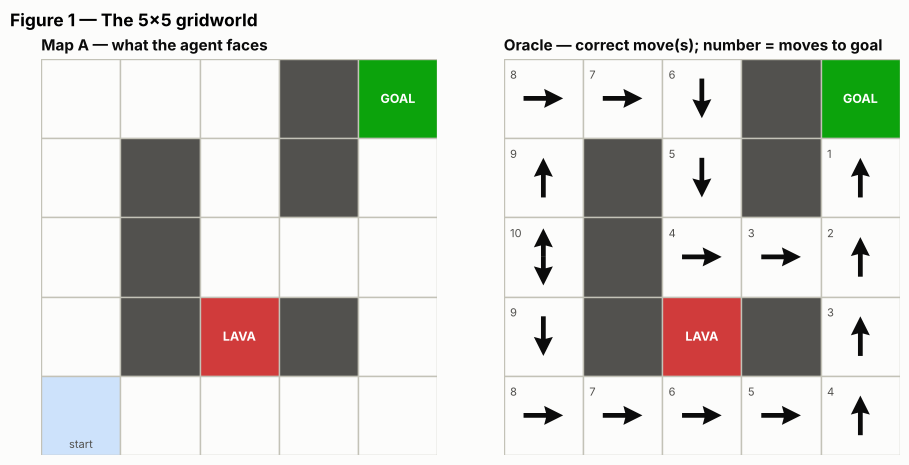

Shortest path from start: 8 moves; 17 non-terminal cells; cells with two correct moves: 1


In [6]:
set_style()


def save(fig, name, folder=None):
    """Save a figure to figures/ (or `folder`) and show it."""
    fig.savefig((folder or FIG) / name)
    plt.show()
    plt.close(fig)


def err_color(e, emax=0.5):
    """Error rate -> one-hue blue ramp (light = few errors, dark = many)."""
    return seq_cmap(RAMP4, "err")(min(e, emax) / emax)


env_A = GridWorld("A")
oracle_A = Oracle(env_A)
fig, axes = plt.subplots(1, 2, figsize=(9.4, 4.7))
draw_grid(axes[0], env_A, fontsize=9)
axes[0].set_title("Map A — what the agent faces")
draw_grid(axes[1], env_A, fontsize=9, show_start=False)
arrows = {"middle": ([], [], [], []), "tail": ([], [], [], [])}
for s in oracle_A.states:
    r, c = env_A.rc(s)
    axes[1].text(c - 0.42, r - 0.30, f"{int(oracle_A.dist[s])}", fontsize=8,
                 color=INK["secondary"], ha="left", va="center")
    best_moves = np.flatnonzero(oracle_A.optimal[s])
    pivot = "middle" if len(best_moves) == 1 else "tail"   # two correct moves: both from centre
    for a in best_moves:
        dr, dc = ACTIONS[a]
        scale = 0.5 if pivot == "middle" else 0.36
        for lst, val in zip(arrows[pivot], (c, r, dc * scale, dr * scale)):
            lst.append(val)
for pivot, (X, Y, U, V) in arrows.items():
    if X:
        axes[1].quiver(X, Y, U, V, angles="xy", scale_units="xy", scale=1, pivot=pivot,
                       color=INK["primary"], width=0.012, headwidth=4.0, headlength=4.0,
                       headaxislength=3.6, zorder=4)
axes[1].set_title("Oracle — correct move(s); number = moves to goal")
fig.suptitle("Figure 1 — The 5×5 gridworld", x=0.01, ha="left")
fig.tight_layout()
save(fig, "fig01_gridworld.png")
print(f"Shortest path from start: {oracle_A.start_dist} moves; "
      f"{len(oracle_A.states)} non-terminal cells; cells with two correct moves: "
      f"{int((oracle_A.optimal.sum(axis=1) > 1).sum())}")

In [7]:
# ---- from src/hitl_gridworld.py, section [agents] ----
class QLearningAgent:
    """Tabular Q-learning (Sutton & Barto, 2018, Sec. 6.5, Eq. 6.8):

        Q(S,A) <- Q(S,A) + alpha * [ R + gamma * max_a Q(S',a) - Q(S,A) ]

    with epsilon-greedy exploration and random tie-breaking."""

    def __init__(self, n_states, n_actions=N_ACTIONS, alpha=0.5, gamma=0.95, epsilon=0.1,
                 q_init=0.0, seed=None):
        self.alpha, self.gamma, self.epsilon = alpha, gamma, epsilon
        self.n_actions = n_actions
        self.Q = np.full((n_states, n_actions), float(q_init))
        self.rng = np.random.default_rng(seed)

    def greedy(self, s):
        q = self.Q[s]
        best = np.flatnonzero(q == q.max())
        return int(best[0]) if best.size == 1 else int(self.rng.choice(best))

    def act(self, s):
        if self.rng.random() < self.epsilon:
            return int(self.rng.integers(self.n_actions))
        return self.greedy(s)

    def update(self, s, a, r, s2, terminated):
        target = r if terminated else r + self.gamma * self.Q[s2].max()
        td_error = target - self.Q[s, a]
        self.Q[s, a] += self.alpha * td_error
        return td_error


class SarsaAgent(QLearningAgent):
    """Sarsa, on-policy TD control (Sutton & Barto, 2018, Sec. 6.4, Eq. 6.7):

        Q(S,A) <- Q(S,A) + alpha * [ R + gamma * Q(S',A') - Q(S,A) ]

    Used only for the Cliff Walking sanity check."""

    def update(self, s, a, r, s2, terminated, a2=None):
        target = r if terminated else r + self.gamma * self.Q[s2, a2]
        td_error = target - self.Q[s, a]
        self.Q[s, a] += self.alpha * td_error
        return td_error


def run_episodes(env, agent, n_episodes, oracle=None, snapshot_at=()):
    """Train `agent` on `env` for `n_episodes`, using only the environment reward.

    Returns per-episode length and return; if an oracle is given, also the policy
    accuracy and whether the greedy path is optimal after each episode; plus copies
    of Q after the episodes in `snapshot_at` (0 = before training)."""
    sarsa = isinstance(agent, SarsaAgent)
    lengths = np.zeros(n_episodes, dtype=int)
    returns = np.zeros(n_episodes)
    accuracy = np.full(n_episodes, np.nan)
    path_ok = np.zeros(n_episodes, dtype=bool)
    snapshots = {0: agent.Q.copy()} if 0 in snapshot_at else {}
    for ep in range(n_episodes):
        s = env.reset()
        a = agent.act(s)
        G = 0.0
        while True:
            s2, r, terminated, truncated = env.step(a)
            G += r
            if sarsa:                        # Sarsa picks A' before updating
                a2 = agent.act(s2)
                agent.update(s, a, r, s2, terminated, a2)
            else:                            # Q-learning picks A' after updating
                agent.update(s, a, r, s2, terminated)
                a2 = None if (terminated or truncated) else agent.act(s2)
            if terminated or truncated:
                break
            s, a = s2, a2
        lengths[ep], returns[ep] = env.t, G
        if oracle is not None:
            accuracy[ep] = policy_accuracy(agent.Q, oracle)
            path_ok[ep] = greedy_path_optimal(agent.Q, env, oracle)
        if ep + 1 in snapshot_at:
            snapshots[ep + 1] = agent.Q.copy()
    return {"length": lengths, "return": returns, "accuracy": accuracy,
            "path_optimal": path_ok, "snapshots": snapshots}


def greedy_route(Q, env, max_len=60):
    """Cells visited when following the greedy policy from the start (for plotting)."""
    s, route = env.start, [env.start]
    for _ in range(max_len):
        a = int(Q[s].argmax())
        s2 = env._T[s][a]
        if s2 == s or env._type[s2] == LAVA:
            break
        route.append(s2)
        s = s2
        if env._type[s] == GOAL:
            break
    return route

### 1a. Sanity check — Cliff Walking (Sutton & Barto, Example 6.6)

Reward −1 per step, −100 for stepping off the cliff (which also sends the agent back to the start), ε = 0.1, α = 0.5, γ = 1. The book reports that Q-learning learns the optimal path along the cliff edge but, because of ε-greedy exploration, keeps falling off, so its *online* reward is worse than Sarsa's, which learns the longer, safer path. Matching this pattern is a check that the agents are implemented correctly.

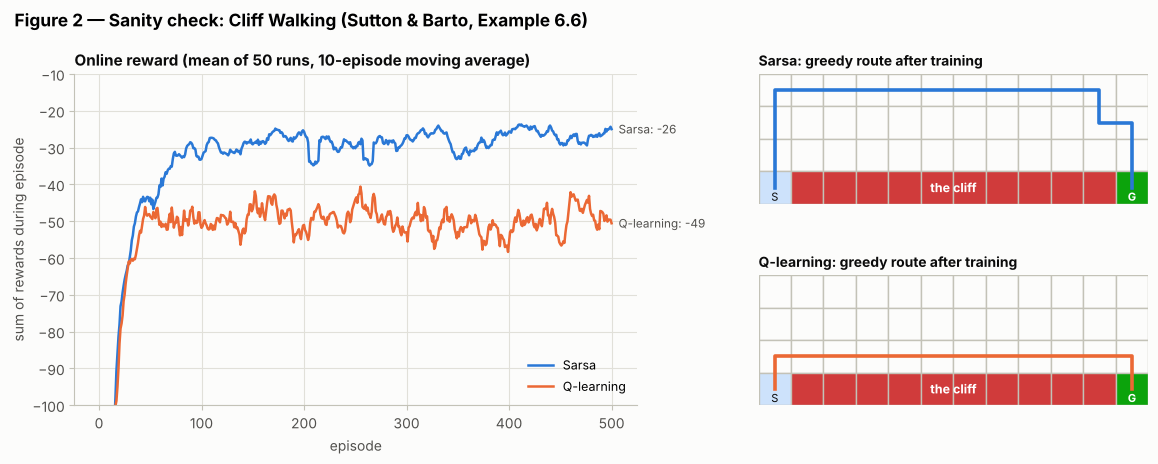

     Sarsa: mean reward per episode over the last 100 episodes = -26.3
Q-learning: mean reward per episode over the last 100 episodes = -48.9


In [8]:
CLIFF_ENV = dict(step_reward=-1.0, goal_reward=-1.0, lava_reward=-100.0, lava_resets=True,
                 max_episode_steps=None)
N_CLIFF_RUNS, N_CLIFF_EPISODES = (10, 300) if FAST else (50, 500)
cliff = {}
for name, cls in (("Sarsa", SarsaAgent), ("Q-learning", QLearningAgent)):
    returns, final_Q = [], []
    for seed in range(N_CLIFF_RUNS):
        env_c = GridWorld("cliff", **CLIFF_ENV)
        agent = cls(env_c.n_states, alpha=0.5, gamma=1.0, epsilon=0.1, seed=seed)
        returns.append(run_episodes(env_c, agent, N_CLIFF_EPISODES)["return"])
        final_Q.append(agent.Q)
    cliff[name] = (np.array(returns), final_Q)


def typical_route(Qs, env):
    """Greedy route of the first run whose greedy policy reaches the goal."""
    for Q in Qs:
        route = greedy_route(Q, env)
        if env.cell_type[route[-1]] == GOAL:
            return route
    return greedy_route(Qs[-1], env)


fig = plt.figure(figsize=(12, 4.6))
gs = fig.add_gridspec(2, 2, width_ratios=[1.25, 1], hspace=0.55)
ax = fig.add_subplot(gs[:, 0])
episodes = np.arange(1, N_CLIFF_EPISODES + 1)
for i, name in enumerate(cliff):
    curve = smooth(cliff[name][0].mean(axis=0), 10)
    ax.plot(episodes, curve, color=CAT[i], label=name)
    label_end(ax, N_CLIFF_EPISODES, curve[-1], f"{name}: {cliff[name][0][:, -100:].mean():.0f}")
ax.set_ylim(-100, -10)
ax.set_xlabel("episode")
ax.set_ylabel("sum of rewards during episode")
ax.set_title(f"Online reward (mean of {N_CLIFF_RUNS} runs, 10-episode moving average)")
ax.legend(loc="lower right")
env_c = GridWorld("cliff", **CLIFF_ENV)
for k, name in enumerate(cliff):
    axm = fig.add_subplot(gs[k, 1])
    draw_grid(axm, env_c, labels=False)
    axm.text(5.5, 3, "the cliff", ha="center", va="center", color="white", fontsize=9,
             weight="bold", zorder=3)
    axm.text(0, 3.28, "S", ha="center", va="center", color=INK["primary"], fontsize=8, zorder=5)
    axm.text(11, 3.28, "G", ha="center", va="center", color="white", fontsize=8,
             weight="bold", zorder=5)
    route = [env_c.rc(s) for s in typical_route(cliff[name][1], env_c)]
    axm.plot([c for r, c in route], [r for r, c in route], color=CAT[k], lw=2.6, zorder=4)
    axm.set_title(f"{name}: greedy route after training", fontsize=10)
fig.suptitle("Figure 2 — Sanity check: Cliff Walking (Sutton & Barto, Example 6.6)",
             x=0.01, ha="left")
fig.subplots_adjust(left=0.06, right=0.98, top=0.84, bottom=0.12, wspace=0.18)
save(fig, "fig02_cliff_walking_check.png")
for name in cliff:
    print(f"{name:>10}: mean reward per episode over the last 100 episodes = "
          f"{cliff[name][0][:, -100:].mean():.1f}")

### 1b. Q-learning on the 5×5 map — learning curves

30 independent runs of 300 episodes each, learning only from the environment reward. Shaded bands are 95 % confidence intervals of the mean.

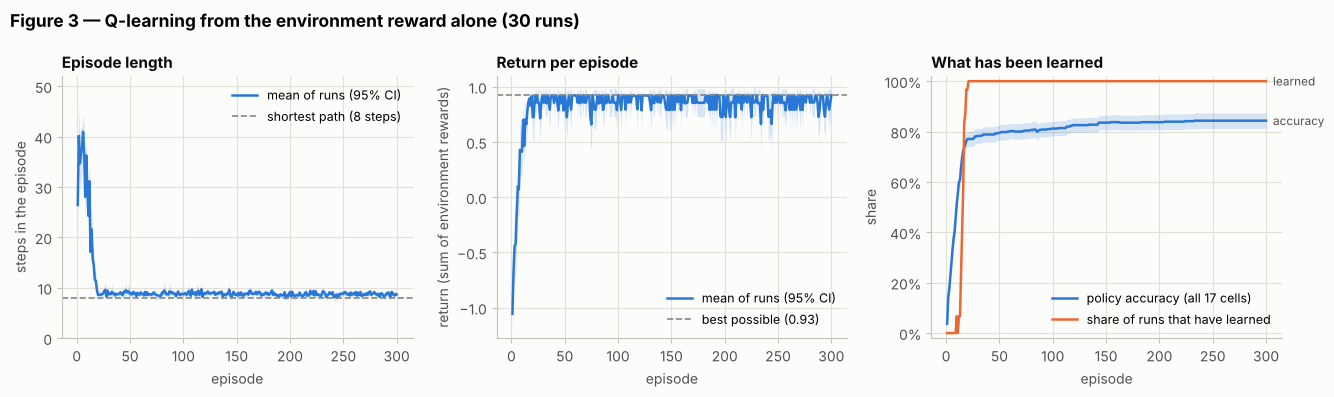

**Part 1 result.** Learning from the environment reward alone, the agent first follows a shortest path after a median of **16 episodes** (≈ **471 environment steps**; 30/30 runs got there). After 300 episodes the greedy action is a shortest-path move in **84%** of cells on average; cells the agent rarely visits (the top-left detour) are learned last.

In [9]:
P1_EPISODES, P1_SEEDS = (150, 12) if FAST else (300, 30)
SNAP_EPISODES = (0, 5, 20, 50, P1_EPISODES)
part1 = []
for seed in range(P1_SEEDS):
    env = GridWorld("A")
    agent = QLearningAgent(env.n_states, alpha=0.5, gamma=0.95, epsilon=0.1, seed=seed)
    part1.append(run_episodes(env, agent, P1_EPISODES, oracle=oracle_A,
                              snapshot_at=SNAP_EPISODES if seed == 0 else ()))
L1 = np.array([r["length"] for r in part1])
R1 = np.array([r["return"] for r in part1])
A1 = np.array([r["accuracy"] for r in part1])
P1 = np.array([r["path_optimal"] for r in part1])
ep = np.arange(1, P1_EPISODES + 1)

fig, axes = plt.subplots(1, 3, figsize=(13, 4.0))
m, h = mean_ci(L1)
axes[0].fill_between(ep, m - h, m + h, color=CAT[0], alpha=0.18, lw=0)
axes[0].plot(ep, m, color=CAT[0], label="mean of runs (95% CI)")
axes[0].axhline(8, color=INK["muted"], ls="--", lw=1.2, label="shortest path (8 steps)")
axes[0].set_ylim(0, 52)
axes[0].set_ylabel("steps in the episode")
axes[0].set_title("Episode length")
axes[0].legend(loc="upper right")
m, h = mean_ci(R1)
axes[1].fill_between(ep, m - h, m + h, color=CAT[0], alpha=0.18, lw=0)
axes[1].plot(ep, m, color=CAT[0], label="mean of runs (95% CI)")
axes[1].axhline(0.93, color=INK["muted"], ls="--", lw=1.2, label="best possible (0.93)")
axes[1].set_ylabel("return (sum of environment rewards)")
axes[1].set_title("Return per episode")
axes[1].legend(loc="lower right")
m, h = mean_ci(A1)
axes[2].fill_between(ep, m - h, m + h, color=CAT[0], alpha=0.18, lw=0)
axes[2].plot(ep, m, color=CAT[0], label="policy accuracy (all 17 cells)")
axes[2].plot(ep, P1.mean(axis=0), color=CAT[1], label="share of runs that have learned")
axes[2].set_ylim(-0.02, 1.02)
axes[2].yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
axes[2].set_ylabel("share")
axes[2].set_title("What has been learned")
axes[2].legend(loc="lower right")
for ax in axes:
    ax.set_xlabel("episode")
fig.suptitle(f"Figure 3 — Q-learning from the environment reward alone ({P1_SEEDS} runs)",
             x=0.01, ha="left")
fig.tight_layout()
label_ends(axes[2], [(P1_EPISODES, m[-1], "accuracy"),
                     (P1_EPISODES, P1.mean(axis=0)[-1], "learned")])
save(fig, "fig03_qlearning_learning_curves.png")

first_ep, first_steps = [], []
for r in part1:
    idx = np.flatnonzero(r["path_optimal"])
    if idx.size:
        first_ep.append(idx[0] + 1)
        first_steps.append(int(r["length"][: idx[0] + 1].sum()))
pd.DataFrame({"episode": ep, "length_mean": L1.mean(0), "return_mean": R1.mean(0),
              "accuracy_mean": A1.mean(0), "share_learned": P1.mean(0)}).to_csv(
    RES / "part1_learning_curves.csv", index=False)
display(Markdown(
    f"**Part 1 result.** Learning from the environment reward alone, the agent first follows a "
    f"shortest path after a median of **{np.median(first_ep):.0f} episodes** "
    f"(≈ **{np.median(first_steps):.0f} environment steps**; {len(first_ep)}/{P1_SEEDS} runs got there). "
    f"After {P1_EPISODES} episodes the greedy action is a shortest-path move in "
    f"**{A1[:, -1].mean():.0%}** of cells on average; cells the agent rarely visits "
    f"(the top-left detour) are learned last."))

### 1c. How the policy develops (one run)

Arrows show the greedy action in each cell (**red** = not a shortest-path move, grey dot = actions still tied); the shading is the state value $V(s)=\max_a Q(s,a)$.

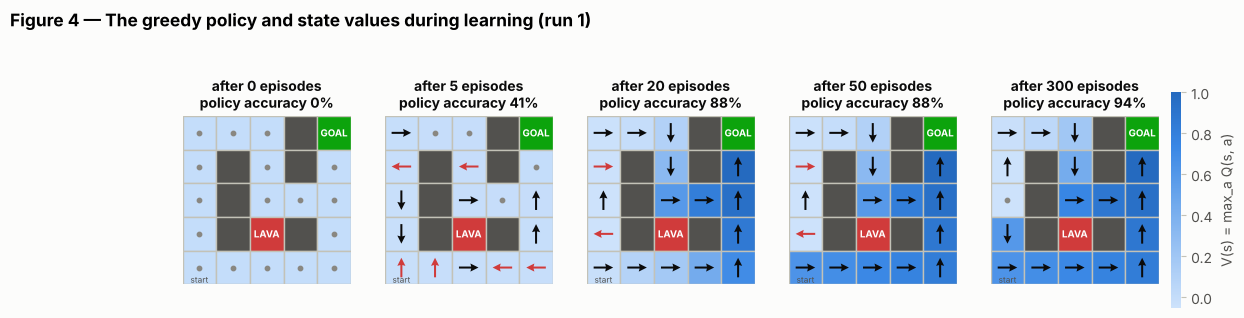

In [10]:
snaps = part1[0]["snapshots"]
fig, axes = plt.subplots(1, len(SNAP_EPISODES), figsize=(3.0 * len(SNAP_EPISODES), 3.5))
values = {k: snaps[k].max(axis=1).astype(float) for k in SNAP_EPISODES}
not_free = env_A.cell_type != FREE
vmin = min(v[~not_free].min() for v in values.values())
vmax = max(v[~not_free].max() for v in values.values())
cmap_v = seq_cmap(BLUE_SEQ[:5], "v")
for ax, k in zip(axes, SNAP_EPISODES):
    v = values[k].copy()
    v[not_free] = np.nan
    draw_grid(ax, env_A, values=v, cmap=cmap_v, vmin=vmin, vmax=vmax, fontsize=7)
    draw_policy(ax, snaps[k], env_A, oracle_A, color=INK["primary"], mark_wrong=True)
    ax.set_title(f"after {k} episodes\npolicy accuracy {policy_accuracy(snaps[k], oracle_A):.0%}",
                 fontsize=10, loc="center")
sm = plt.cm.ScalarMappable(norm=Normalize(vmin, vmax), cmap=cmap_v)
cb = fig.colorbar(sm, ax=list(axes), shrink=0.8, pad=0.01)
cb.set_label("V(s) = max_a Q(s, a)", color=INK["secondary"])
cb.outline.set_visible(False)
fig.suptitle("Figure 4 — The greedy policy and state values during learning (run 1)",
             x=0.01, ha="left", y=1.04)
save(fig, "fig04_policy_snapshots.png")

### 1d. The learned Q-table

One panel per action: the learned value of taking that action in each cell (end of run 1).

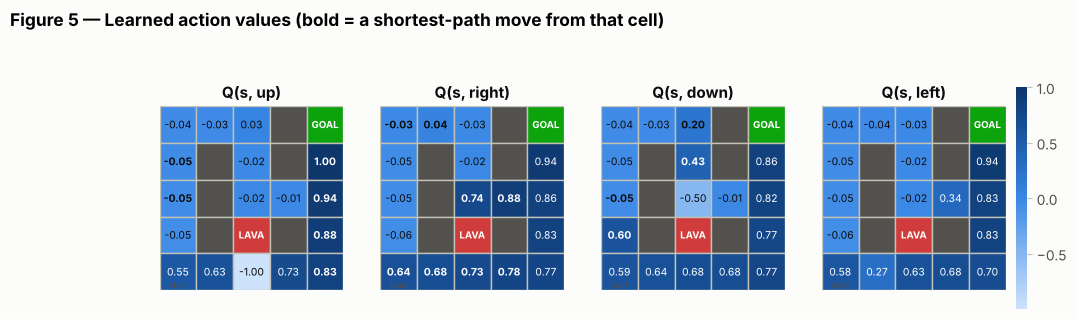

In [11]:
Q_final = snaps[P1_EPISODES]
free_states = oracle_A.states
qmin, qmax = Q_final[free_states].min(), Q_final[free_states].max()
cmap_q = seq_cmap(BLUE_SEQ, "q")
fig, axes = plt.subplots(1, 4, figsize=(13, 3.6))
for a, ax in enumerate(axes):
    vals = np.full(env_A.n_states, np.nan)
    vals[free_states] = Q_final[free_states, a]
    draw_grid(ax, env_A, values=vals, cmap=cmap_q, vmin=qmin, vmax=qmax, fontsize=7)
    for s in free_states:
        r, c = env_A.rc(s)
        shade = (Q_final[s, a] - qmin) / (qmax - qmin + 1e-12)
        best = oracle_A.optimal[s, a]
        ax.text(c, r, f"{Q_final[s, a]:.2f}", ha="center", va="center", fontsize=7.5,
                color="white" if shade > 0.6 else INK["primary"],
                weight="bold" if best else "normal", zorder=3)
    ax.set_title(f"Q(s, {ACTION_NAMES[a]})", loc="center")
sm = plt.cm.ScalarMappable(norm=Normalize(qmin, qmax), cmap=cmap_q)
cb = fig.colorbar(sm, ax=list(axes), shrink=0.8, pad=0.01)
cb.outline.set_visible(False)
fig.suptitle("Figure 5 — Learned action values (bold = a shortest-path move from that cell)",
             x=0.01, ha="left", y=1.02)
save(fig, "fig05_q_values.png")

## Part 2 — A simulated trainer who is sometimes wrong and sometimes silent

Real people are imperfect trainers: they press the wrong key, misjudge a move, or simply say nothing. Following the simulated-teacher method of Griffith et al. (2013) — whose *Advise* model describes feedback by its **consistency** $C$ and its **likelihood** $L$ — and the "mistake" teacher of the B-Pref benchmark (Lee et al., 2021), the simulated trainer here

* decides at each move whether to speak at all: it gives feedback with probability **p** and otherwise stays **silent** ($h = 0$);
* when it speaks, it says **+1** for a correct move (one that shortens the path to the goal) and **−1** otherwise — but with probability **e** it gives the *wrong* sign.

So $C = 1 - e$ and $L = p$. The agent simply treats feedback as extra reward (*reward shaping* with human feedback; cf. Knox & Stone, 2010):

$$r_{\text{total}} = r_{\text{env}} + \beta\,h,\qquad h \in \{+1, -1, 0\},\quad \beta = 1 .$$

This is the simplest way to use feedback and it has known weaknesses — e.g. feedback treated as reward can create positive reward cycles (MacGlashan et al., 2017) — which is part of why errors matter. Every condition uses the same 50 random seeds. **Time to learn** = environment steps until the greedy path from the start is optimal; runs that never get there within 4 000 steps are counted as 4 000 (shown as *did not learn*).

In [12]:
# ---- from src/hitl_gridworld.py, section [trainer] ----
class SimulatedTrainer:
    """A simulated person who watches every move and may press GOOD (+1) or BAD (-1).

    The trainer knows the shortest-path oracle, but
      * speaks only with probability `feedback_prob` (otherwise silent: h = 0), and
      * when speaking, gives the wrong sign with probability `error_rate`.
    The counters record how much feedback was given and how much of it was correct."""

    def __init__(self, oracle, error_rate=0.0, feedback_prob=1.0, seed=None):
        if not (0.0 <= error_rate <= 1.0 and 0.0 <= feedback_prob <= 1.0):
            raise ValueError("error_rate and feedback_prob must be in [0, 1]")
        self.oracle, self.error_rate, self.feedback_prob = oracle, error_rate, feedback_prob
        self.rng = np.random.default_rng(seed)
        self.n_given = 0
        self.n_correct = 0

    def __call__(self, s, a):
        if self.feedback_prob <= 0.0 or self.rng.random() >= self.feedback_prob:
            return 0
        good = self.oracle._opt[s][a]
        h = 1 if good else -1
        if self.rng.random() < self.error_rate:
            h = -h
        self.n_given += 1
        self.n_correct += int((h > 0) == good)
        return h


def run_with_trainer(layout="A", error_rate=0.0, feedback_prob=1.0, seed=0, max_steps=3000,
                     alpha=0.5, gamma=0.95, epsilon=0.1, beta=1.0, record_every=10,
                     stop_when_learned=False, env_kwargs=None):
    """One run of Q-learning with a simulated trainer.

    The agent learns from   r_total = r_env + beta * h,   with h in {+1, -1, 0} the
    trainer's feedback on the action just taken (human feedback as reward shaping).

    Returns a dict with
      steps_to_learn     environment steps until the greedy path from the start is
                         optimal (np.nan if that did not happen within max_steps)
      feedback_to_learn  feedback signals given until then (all of them, if never learned)
      correct_to_learn   how many of those were correct
      accuracy_curve     policy accuracy (all cells) every `record_every` steps
      route_curve        policy accuracy on the shortest route, every `record_every` steps
      learned_curve      whether the greedy path was optimal, every `record_every` steps
    """
    env = GridWorld(layout, **(env_kwargs or {}))
    oracle = Oracle(env)
    agent_seed, trainer_seed = np.random.SeedSequence(seed).spawn(2)
    agent = QLearningAgent(env.n_states, alpha=alpha, gamma=gamma, epsilon=epsilon,
                           seed=agent_seed)
    trainer = SimulatedTrainer(oracle, error_rate, feedback_prob, seed=trainer_seed)
    n_points = max_steps // record_every if record_every else 0
    acc_curve = np.full(n_points, np.nan)
    route_curve = np.full(n_points, np.nan)
    learned_curve = np.zeros(n_points, dtype=bool)
    steps_to_learn = np.nan
    fb_to_learn = correct_to_learn = None
    episodes = 1
    s = env.reset()
    for t in range(1, max_steps + 1):
        a = agent.act(s)
        s2, r, terminated, truncated = env.step(a)
        h = trainer(s, a)
        agent.update(s, a, r + beta * h, s2, terminated)
        if np.isnan(steps_to_learn) and greedy_path_optimal(agent.Q, env, oracle):
            steps_to_learn = float(t)
            fb_to_learn, correct_to_learn = trainer.n_given, trainer.n_correct
            if stop_when_learned:
                break
        if n_points and t % record_every == 0:
            i = t // record_every - 1
            acc_curve[i] = policy_accuracy(agent.Q, oracle)
            route_curve[i] = route_accuracy(agent.Q, oracle)
            learned_curve[i] = greedy_path_optimal(agent.Q, env, oracle)
        if terminated or truncated:
            s = env.reset()
            episodes += 1
        else:
            s = s2
    if fb_to_learn is None:
        fb_to_learn, correct_to_learn = trainer.n_given, trainer.n_correct
    return {
        "error_rate": error_rate, "feedback_prob": feedback_prob, "seed": seed,
        "steps_to_learn": steps_to_learn, "learned": bool(not np.isnan(steps_to_learn)),
        "feedback_to_learn": fb_to_learn, "correct_to_learn": correct_to_learn,
        "feedback_total": trainer.n_given, "correct_total": trainer.n_correct,
        "episodes": episodes, "accuracy_curve": acc_curve, "route_curve": route_curve,
        "learned_curve": learned_curve, "final_accuracy": policy_accuracy(agent.Q, oracle),
        "Q": agent.Q,
    }


def run_many(n_seeds, seed0=0, **kwargs):
    """run_with_trainer over seeds seed0 .. seed0 + n_seeds - 1. Every condition uses the
    same seeds, so conditions are compared on matched random streams."""
    return [run_with_trainer(seed=seed0 + i, **kwargs) for i in range(n_seeds)]


def censored_steps(runs, max_steps):
    """steps_to_learn of each run, with runs that never learned set to max_steps."""
    x = np.array([r["steps_to_learn"] for r in runs], dtype=float)
    return np.where(np.isnan(x), float(max_steps), x)


def sweep(error_rates, feedback_probs, n_seeds, max_steps=3000, **kwargs):
    """Time-to-learn for every (error rate, feedback probability) pair. One row per run."""
    rows = []
    for p in feedback_probs:
        for e in error_rates:
            for i in range(n_seeds):
                r = run_with_trainer(error_rate=e, feedback_prob=p, seed=i, max_steps=max_steps,
                                     record_every=0, stop_when_learned=True, **kwargs)
                rows.append({k: r[k] for k in ("error_rate", "feedback_prob", "seed",
                                               "steps_to_learn", "learned",
                                               "feedback_to_learn", "correct_to_learn",
                                               "episodes")})
    df = pd.DataFrame(rows)
    df["steps_to_learn_c"] = df["steps_to_learn"].fillna(float(max_steps))
    return df

In [13]:
# Check: does the simulated trainer speak and err at the rates we asked for?
check = SimulatedTrainer(oracle_A, error_rate=0.3, feedback_prob=0.5, seed=0)
rng = np.random.default_rng(0)
calls = [(int(rng.choice(oracle_A.states)), int(rng.integers(N_ACTIONS))) for _ in range(100_000)]
h = np.array([check(s, a) for s, a in calls])
print(f"asked p = 0.50 -> spoke on {np.mean(h != 0):.3f} of steps; "
      f"asked e = 0.30 -> wrong in {1 - check.n_correct / check.n_given:.3f} of its feedback")

asked p = 0.50 -> spoke on 0.500 of steps; asked e = 0.30 -> wrong in 0.298 of its feedback


### 2a. The baseline: plain Q-learning, and its sensitivity to α and ε

Before adding a trainer: how many environment steps does the agent need on its own (median of 20 runs per cell)? The box marks the setting used everywhere else (α = 0.5, ε = 0.1).

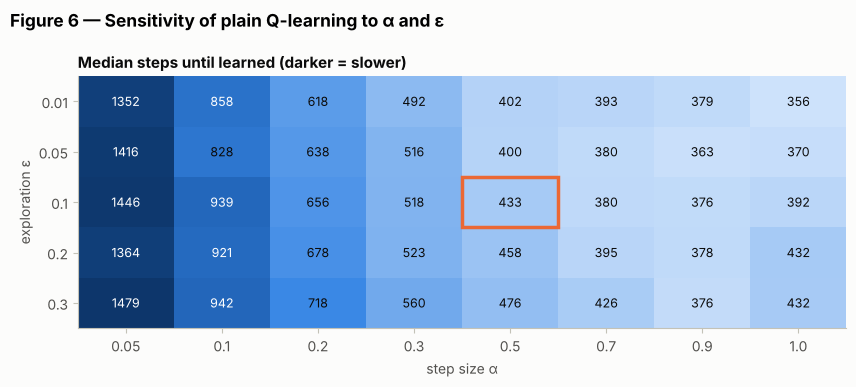

In [14]:
ALPHAS = [0.05, 0.1, 0.2, 0.3, 0.5, 0.7, 0.9, 1.0]
EPSILONS = [0.01, 0.05, 0.1, 0.2, 0.3]
N_SENS = 6 if FAST else 20
sens = np.zeros((len(EPSILONS), len(ALPHAS)))
for i, eps in enumerate(EPSILONS):
    for j, al in enumerate(ALPHAS):
        runs = run_many(N_SENS, feedback_prob=0.0, alpha=al, epsilon=eps, max_steps=8000,
                        record_every=0, stop_when_learned=True)
        sens[i, j] = np.median(censored_steps(runs, 8000))
pd.DataFrame(sens, index=[f"eps={e}" for e in EPSILONS],
             columns=[f"alpha={a}" for a in ALPHAS]).to_csv(RES / "part1_sensitivity.csv")

fig, ax = plt.subplots(figsize=(8.6, 3.9))
norm = matplotlib.colors.LogNorm(vmin=sens.min(), vmax=sens.max())
cmap_s = seq_cmap(BLUE_SEQ, "s")
ax.imshow(sens, cmap=cmap_s, norm=norm, aspect="auto")
for i in range(len(EPSILONS)):
    for j in range(len(ALPHAS)):
        dark = norm(sens[i, j]) > 0.6
        ax.text(j, i, f"{sens[i, j]:.0f}", ha="center", va="center", fontsize=9,
                color="white" if dark else INK["primary"])
j0, i0 = ALPHAS.index(0.5), EPSILONS.index(0.1)
ax.add_patch(Rectangle((j0 - 0.5, i0 - 0.5), 1, 1, fill=False, edgecolor=MOVE_COLOR, lw=2.5))
ax.set_xticks(range(len(ALPHAS)))
ax.set_xticklabels([str(a) for a in ALPHAS])
ax.set_yticks(range(len(EPSILONS)))
ax.set_yticklabels([str(e) for e in EPSILONS])
ax.set_xlabel("step size α")
ax.set_ylabel("exploration ε")
ax.grid(False)
ax.set_title("Median steps until learned (darker = slower)")
fig.suptitle("Figure 6 — Sensitivity of plain Q-learning to α and ε", x=0.01, ha="left")
fig.tight_layout()
save(fig, "fig06_sensitivity_alpha_epsilon.png")

### 2b. Learning curves with a noisy trainer

Left: feedback on every step. Right: the trainer is silent half the time. The dashed grey line is the agent learning from the environment alone. **Top row:** the 8 cells of the shortest route — the part of the policy that the *learned* criterion (and the task) depends on. **Bottom row:** all 17 cells.

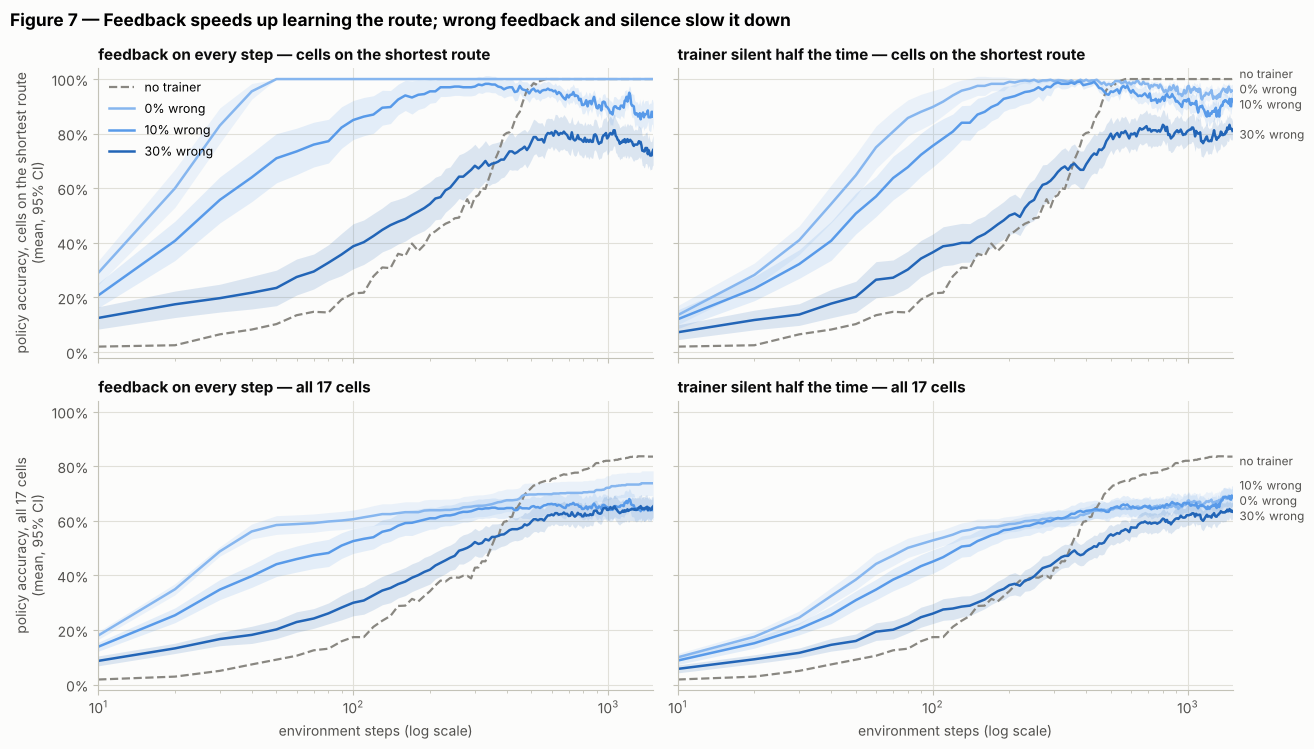

policy accuracy over all 17 cells after 1500 steps: no trainer 84%; perfect trainer 74%; 10% wrong 64%; 30% wrong 65%


In [15]:
CURVE_STEPS = 1500
CURVE_CONDS = [(0.0, 0.0)] + [(e, p) for p in (1.0, 0.5) for e in (0.0, 0.1, 0.3)]
curves = {(e, p): run_many(N_SEEDS, error_rate=e, feedback_prob=p, max_steps=CURVE_STEPS,
                           record_every=10) for e, p in CURVE_CONDS}
t_axis = np.arange(10, CURVE_STEPS + 1, 10)


def cond_label(e, p):
    return "no trainer" if p == 0 else f"{e:.0%} wrong"


fig, axes = plt.subplots(2, 2, figsize=(12.5, 7.6), sharex=True, sharey=True)
end_labels = {}
for row, (key, what) in enumerate((("route_curve", "cells on the shortest route"),
                                   ("accuracy_curve", "all 17 cells"))):
    for col, p in enumerate((1.0, 0.5)):
        ax = axes[row, col]
        end_labels[ax] = []
        m, hw = mean_ci(np.array([r[key] for r in curves[(0.0, 0.0)]]))
        ax.plot(t_axis, m, color=INK["muted"], ls="--", lw=1.6, label="no trainer")
        end_labels[ax].append((CURVE_STEPS, m[-1], "no trainer"))
        for e in (0.0, 0.1, 0.3):
            m, hw = mean_ci(np.array([r[key] for r in curves[(e, p)]]))
            ax.fill_between(t_axis, m - hw, m + hw, color=err_color(e), alpha=0.15, lw=0)
            ax.plot(t_axis, m, color=err_color(e), label=cond_label(e, p))
            end_labels[ax].append((CURVE_STEPS, m[-1], cond_label(e, p)))
        ax.set_xscale("log")
        ax.set_xlim(10, CURVE_STEPS)
        ax.set_ylim(-0.02, 1.04)
        ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
        feedback = "feedback on every step" if p == 1 else "trainer silent half the time"
        ax.set_title(f"{feedback} — {what}")
        if row == 1:
            ax.set_xlabel("environment steps (log scale)")
        if col == 0:
            ax.set_ylabel(f"policy accuracy, {what}\n(mean, 95% CI)")
axes[0, 0].legend(loc="upper left")
fig.suptitle("Figure 7 — Feedback speeds up learning the route; wrong feedback and silence "
             "slow it down", x=0.01, ha="left")
fig.tight_layout()
for ax in axes[:, 1]:                     # left column: the legend names the lines
    label_ends(ax, end_labels[ax])
save(fig, "fig07_trainer_learning_curves.png")
late = {k: np.mean([r["accuracy_curve"][-1] for r in v]) for k, v in curves.items()}
print("policy accuracy over all 17 cells after "
      f"{CURVE_STEPS} steps: no trainer {late[(0.0, 0.0)]:.0%}; perfect trainer "
      f"{late[(0.0, 1.0)]:.0%}; 10% wrong {late[(0.1, 1.0)]:.0%}; 30% wrong {late[(0.3, 1.0)]:.0%}")

**Top row:** with wrong feedback the route is not only learned later, it also does not *stay* learned — each wrong signal can flip an action back (with α = 0.5 the agent reacts strongly to single signals), so the curves sag after their peak.

**A side effect worth noticing (bottom row).** Over the whole map, the agent without a trainer ends up knowing *more* cells than the trained agents. Once the trainer has rewarded the route, the agent keeps to it and rarely explores cells it does not need, so their greedy actions stay unlearned or wrong. This matters for the pilot: the policy-arrow display will show some wrong arrows in cells the agent hardly visits, and a person cannot fix them — feedback only reaches moves the agent actually makes.

### 2c. When has the agent learned?

The share of runs whose greedy path is already optimal at each step (a curve further right = slower learning).

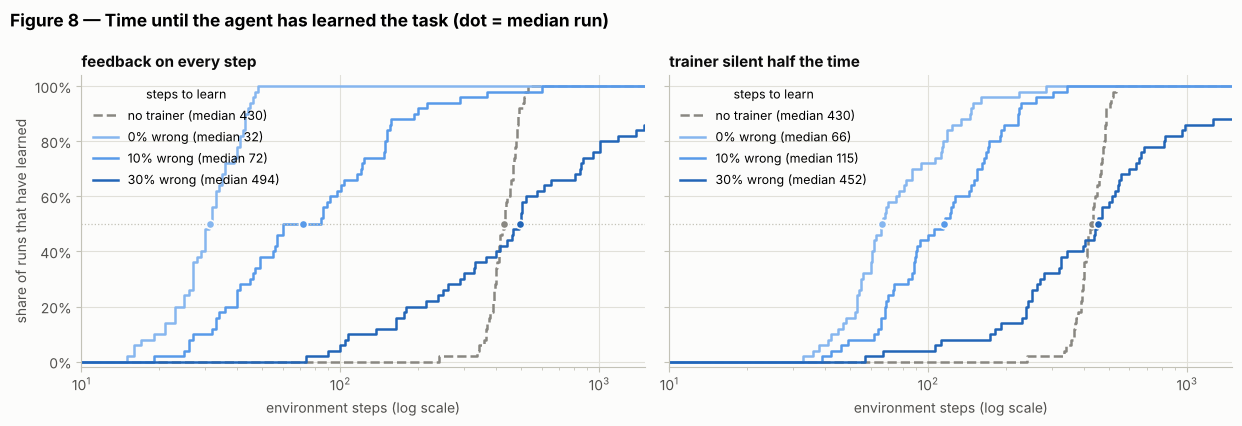

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.3), sharey=True)
for ax, p in zip(axes, (1.0, 0.5)):
    for (e, pp), style in [((0.0, 0.0), "base")] + [((e, p), "t") for e in (0.0, 0.1, 0.3)]:
        x = censored_steps(curves[(e, pp)], CURVE_STEPS * 10)
        grid = np.unique(np.concatenate([[1], np.sort(x), [CURVE_STEPS]]))
        share = [(x <= g).mean() for g in grid]
        color = INK["muted"] if style == "base" else err_color(e)
        median = np.median(x)
        med_txt = f"median {median:.0f}" if median <= CURVE_STEPS else f"median > {CURVE_STEPS}"
        ax.step(grid, share, where="post", color=color, ls="--" if style == "base" else "-",
                lw=1.8, label=f"{cond_label(e, pp)} ({med_txt})")
        if median <= CURVE_STEPS:
            ax.scatter([median], [0.5], s=36, color=color, edgecolor=INK["surface"], lw=1.2,
                       zorder=4)
    ax.axhline(0.5, color=INK["axis"], lw=0.9, ls=":")
    ax.set_xscale("log")
    ax.set_xlim(10, CURVE_STEPS)
    ax.set_ylim(-0.02, 1.04)
    ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
    ax.set_xlabel("environment steps (log scale)")
    ax.set_title("feedback on every step" if p == 1 else "trainer silent half the time")
    ax.legend(loc="upper left", title="steps to learn", title_fontsize=9)
axes[0].set_ylabel("share of runs that have learned")
fig.suptitle("Figure 8 — Time until the agent has learned the task (dot = median run)",
             x=0.01, ha="left")
fig.tight_layout()
save(fig, "fig08_time_to_learn_cdf.png")

### 2d. The full picture: error rate × silence

Every combination of 9 error rates and 5 feedback rates, 50 runs each (≈ 2 250 runs).

In [17]:
ERRORS = [0.0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3, 0.4, 0.5]
PROBS = [1.0, 0.75, 0.5, 0.25, 0.1]
t0 = time.time()
sw = sweep(ERRORS, PROBS, N_SEEDS, max_steps=MAX_STEPS)
base = sweep([0.0], [0.0], N_SEEDS, max_steps=MAX_STEPS)      # learning from the environment alone
sw.to_csv(RES / "part2_sweep.csv", index=False)
base.to_csv(RES / "part2_no_trainer.csv", index=False)
BASE_MED = float(base["steps_to_learn_c"].median())
summary = (sw.groupby(["feedback_prob", "error_rate"])
             .agg(median=("steps_to_learn_c", "median"),
                  q25=("steps_to_learn_c", lambda x: x.quantile(0.25)),
                  q75=("steps_to_learn_c", lambda x: x.quantile(0.75)),
                  learned=("learned", "mean"),
                  feedback=("feedback_to_learn", "mean"),
                  correct=("correct_to_learn", "mean"))
             .reset_index())
summary["speedup_vs_no_trainer"] = BASE_MED / summary["median"]
summary.to_csv(RES / "part2_summary.csv", index=False)
print(f"{len(sw) + len(base)} runs in {time.time() - t0:.0f} s; "
      f"no trainer: median {BASE_MED:.0f} steps to learn")
display(summary.pivot(index="feedback_prob", columns="error_rate", values="median")
        .sort_index(ascending=False).round(0))

2300 runs in 23 s; no trainer: median 430 steps to learn


error_rate,0.00,0.05,0.10,0.15,0.20,0.25,0.30,0.40,0.50
feedback_prob,,,,,,,,,
1.00,32.0,42.0,72.0,101.0,170.0,204.0,494.0,1694.0,4000.0
0.75,50.0,59.0,83.0,105.0,144.0,214.0,292.0,1756.0,4000.0
0.50,66.0,91.0,115.0,156.0,286.0,331.0,452.0,1848.0,4000.0
0.25,119.0,158.0,193.0,261.0,372.0,460.0,614.0,1266.0,4000.0
0.10,233.0,242.0,306.0,342.0,498.0,634.0,806.0,1750.0,4000.0


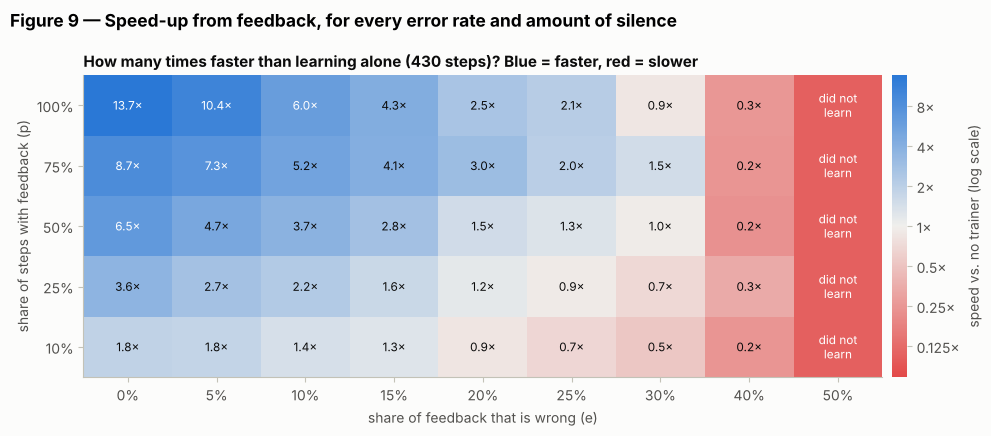

In [18]:
med_grid = (summary.pivot(index="feedback_prob", columns="error_rate", values="median")
            .sort_index(ascending=False))
learn_grid = (summary.pivot(index="feedback_prob", columns="error_rate", values="learned")
              .sort_index(ascending=False))
speed = np.log2(BASE_MED / med_grid.values)
fig, ax = plt.subplots(figsize=(10.5, 4.4))
lim = np.nanmax(np.abs(speed))
norm = matplotlib.colors.TwoSlopeNorm(vmin=-lim, vcenter=0.0, vmax=lim)
im = ax.imshow(speed, cmap=div_cmap(), norm=norm, aspect="auto")
for i in range(speed.shape[0]):
    for j in range(speed.shape[1]):
        if learn_grid.values[i, j] < 0.5:
            txt = "did not\nlearn"
        else:
            txt = f"{2 ** speed[i, j]:.1f}×"
        ax.text(j, i, txt, ha="center", va="center", fontsize=8.5,
                color="white" if abs(norm(speed[i, j]) - 0.5) > 0.33 else INK["primary"])
ax.set_xticks(range(len(ERRORS)))
ax.set_xticklabels([f"{e:.0%}" for e in ERRORS])
ax.set_yticks(range(len(med_grid.index)))
ax.set_yticklabels([f"{p:.0%}" for p in med_grid.index])
ax.set_xlabel("share of feedback that is wrong (e)")
ax.set_ylabel("share of steps with feedback (p)")
ax.grid(False)
cb = fig.colorbar(im, ax=ax, pad=0.01)
cb.set_label("speed vs. no trainer (log scale)", color=INK["secondary"])
ticks = [t for t in (-3, -2, -1, 0, 1, 2, 3, 4) if -lim <= t <= lim]
cb.set_ticks(ticks)
cb.set_ticklabels([f"{2 ** t:g}×" for t in ticks])
cb.outline.set_visible(False)
ax.set_title(f"How many times faster than learning alone ({BASE_MED:.0f} steps)? "
             "Blue = faster, red = slower")
fig.suptitle("Figure 9 — Speed-up from feedback, for every error rate and amount of silence",
             x=0.01, ha="left")
fig.tight_layout()
save(fig, "fig09_speedup_heatmap.png")

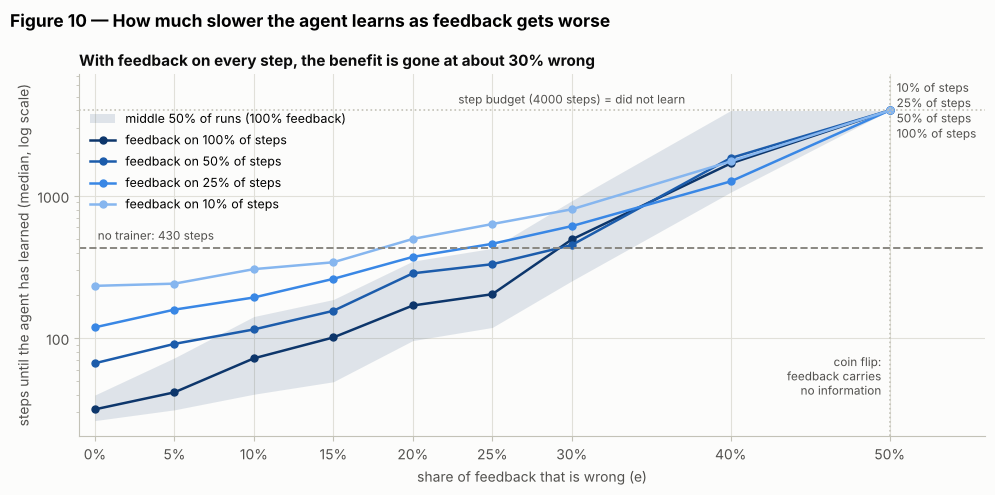

In [19]:
every_step = summary[summary["feedback_prob"] == 1.0].sort_values("error_rate")
no_gain = every_step[every_step["median"] >= BASE_MED]["error_rate"]
CROSSOVER = float(no_gain.iloc[0]) if len(no_gain) else float("nan")

fig, ax = plt.subplots(figsize=(10, 5.0))
p_colors = dict(zip([0.1, 0.25, 0.5, 1.0], RAMP4))
ends = []
for p in [1.0, 0.5, 0.25, 0.1]:
    g = summary[summary["feedback_prob"] == p].sort_values("error_rate")
    if p == 1.0:
        ax.fill_between(g["error_rate"], g["q25"], g["q75"], color=p_colors[p], alpha=0.12,
                        lw=0, label="middle 50% of runs (100% feedback)")
    ax.plot(g["error_rate"], g["median"], marker="o", ms=5, color=p_colors[p],
            label=f"feedback on {p:.0%} of steps")
    ends.append((g["error_rate"].iloc[-1], g["median"].iloc[-1], f"{p:.0%} of steps"))
ax.axhline(BASE_MED, color=INK["muted"], ls="--", lw=1.4)
ax.annotate(f"no trainer: {BASE_MED:.0f} steps", xy=(0.0, BASE_MED), xytext=(2, 6),
            textcoords="offset points", fontsize=8.5, color=INK["secondary"])
ax.axhline(MAX_STEPS, color=INK["axis"], ls=":", lw=1.2)
ax.annotate(f"step budget ({MAX_STEPS} steps) = did not learn", xy=(0.3, MAX_STEPS),
            xytext=(0, 5), textcoords="offset points", ha="center", fontsize=8.5,
            color=INK["secondary"])
ax.axvline(0.5, color=INK["axis"], ls=":", lw=1.2)
ax.annotate("coin flip:\nfeedback carries\nno information", xy=(0.5, 40), xytext=(-6, 0),
            textcoords="offset points", ha="right", fontsize=8.5, color=INK["secondary"])
ax.set_yscale("log")
ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:g}"))
ax.set_xticks(ERRORS)
ax.set_xticklabels([f"{e:.0%}" for e in ERRORS])
ax.set_xlim(-0.01, 0.56)
ax.set_ylim(top=MAX_STEPS * 1.8)
ax.set_xlabel("share of feedback that is wrong (e)")
ax.set_ylabel("steps until the agent has learned (median, log scale)")
ax.legend(loc="upper left", bbox_to_anchor=(0.0, 0.93))
ax.set_title(f"With feedback on every step, the benefit is gone at about {CROSSOVER:.0%} wrong")
fig.suptitle("Figure 10 — How much slower the agent learns as feedback gets worse",
             x=0.01, ha="left")
fig.tight_layout()
label_ends(ax, ends)
save(fig, "fig10_slowdown_vs_error.png")

### 2e. How much feedback is needed — and how much of it is wrong

Mean number of key presses the simulated trainer gave before the agent learned, split into correct and wrong ones.

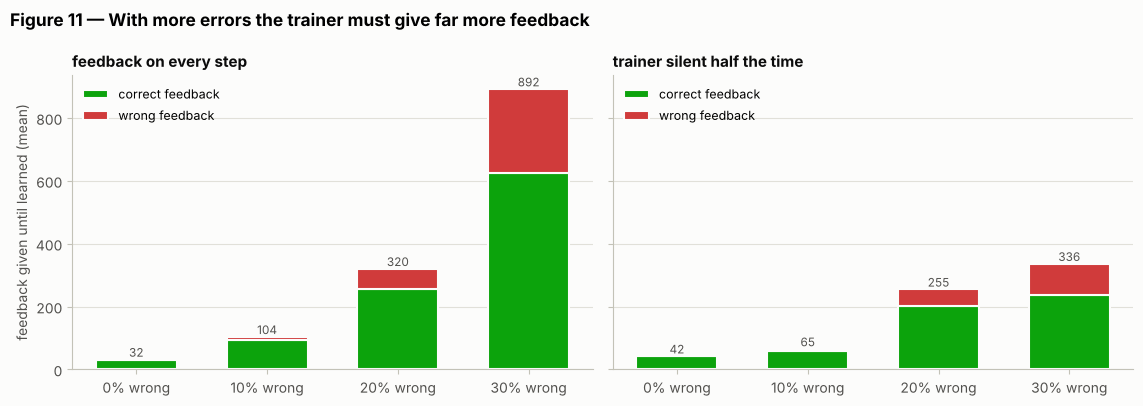

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.1), sharey=True)
show_errors = [0.0, 0.1, 0.2, 0.3]
for ax, p in zip(axes, (1.0, 0.5)):
    g = summary[(summary["feedback_prob"] == p) & summary["error_rate"].isin(show_errors)]
    g = g.sort_values("error_rate")
    x = np.arange(len(g))
    correct = g["correct"].values
    wrong = g["feedback"].values - correct
    ax.bar(x, correct, width=0.62, color=STATUS["good"], edgecolor=INK["surface"], lw=1.5,
           label="correct feedback")
    ax.bar(x, wrong, width=0.62, bottom=correct, color=STATUS["critical"],
           edgecolor=INK["surface"], lw=1.5, label="wrong feedback")
    for xi, c_, w_ in zip(x, correct, wrong):
        ax.text(xi, c_ + w_, f"{c_ + w_:.0f}", ha="center", va="bottom", fontsize=8.5,
                color=INK["secondary"])
    ax.set_xticks(x)
    ax.set_xticklabels([f"{e:.0%} wrong" for e in g["error_rate"]])
    ax.set_title("feedback on every step" if p == 1 else "trainer silent half the time")
    ax.grid(axis="x", visible=False)
    ax.legend(loc="upper left")
axes[0].set_ylabel("feedback given until learned (mean)")
fig.suptitle("Figure 11 — With more errors the trainer must give far more feedback",
             x=0.01, ha="left")
fig.tight_layout()
save(fig, "fig11_feedback_needed.png")

### 2f. Does a more cautious learner tolerate errors better?

Same experiment (trainer silent half the time) for four step sizes α. The y-axis is the speed-up over the same agent learning alone; below 1× the feedback hurts.

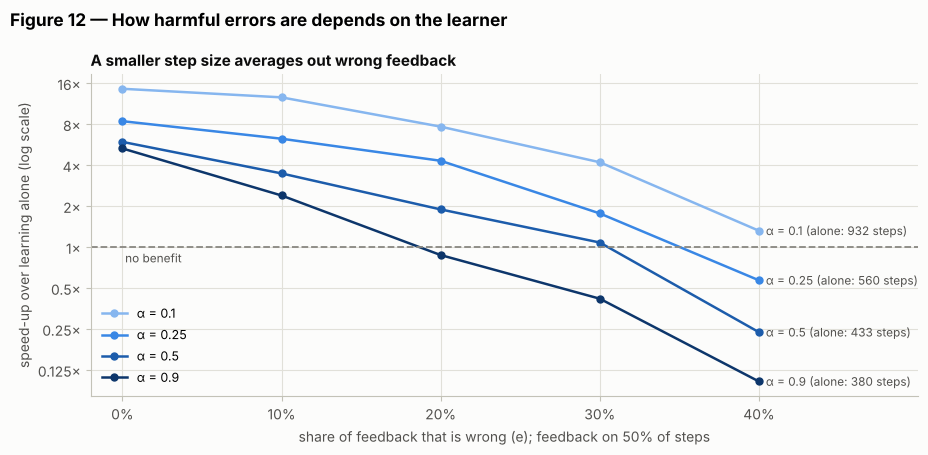

In [21]:
ALPHA_SET = [0.1, 0.25, 0.5, 0.9]
ERR_SET = [0.0, 0.1, 0.2, 0.3, 0.4]
N_ALPHA = 8 if FAST else 30
rows = []
for al in ALPHA_SET:
    alone = np.median(censored_steps(run_many(N_ALPHA, feedback_prob=0.0, alpha=al,
                                              max_steps=MAX_STEPS, record_every=0,
                                              stop_when_learned=True), MAX_STEPS))
    for e in ERR_SET:
        runs = run_many(N_ALPHA, error_rate=e, feedback_prob=0.5, alpha=al, max_steps=MAX_STEPS,
                        record_every=0, stop_when_learned=True)
        med_steps = np.median(censored_steps(runs, MAX_STEPS))
        rows.append({"alpha": al, "error_rate": e, "median": med_steps, "alone": alone,
                     "speedup": alone / med_steps})
alpha_df = pd.DataFrame(rows)
alpha_df.to_csv(RES / "part2_alpha_sensitivity.csv", index=False)

fig, ax = plt.subplots(figsize=(9.5, 4.6))
for k, al in enumerate(ALPHA_SET):
    g = alpha_df[alpha_df["alpha"] == al]
    ax.plot(g["error_rate"], g["speedup"], marker="o", ms=5, color=RAMP4[k], label=f"α = {al}")
    label_end(ax, g["error_rate"].iloc[-1], g["speedup"].iloc[-1],
              f"α = {al} (alone: {g['alone'].iloc[0]:.0f} steps)")
ax.axhline(1.0, color=INK["muted"], ls="--", lw=1.3)
ax.annotate("no benefit", xy=(0.0, 1.0), xytext=(2, -11), textcoords="offset points",
            fontsize=8.5, color=INK["secondary"])
ax.set_yscale("log", base=2)
ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:g}×"))
ax.set_xticks(ERR_SET)
ax.set_xticklabels([f"{e:.0%}" for e in ERR_SET])
ax.set_xlim(-0.02, 0.5)
ax.set_xlabel("share of feedback that is wrong (e); feedback on 50% of steps")
ax.set_ylabel("speed-up over learning alone (log scale)")
ax.legend(loc="lower left")
ax.set_title("A smaller step size averages out wrong feedback")
fig.suptitle("Figure 12 — How harmful errors are depends on the learner", x=0.01, ha="left")
fig.tight_layout()
save(fig, "fig12_alpha_vs_error.png")

In [22]:
med = summary.set_index(["feedback_prob", "error_rate"])["median"]
lrn = summary.set_index(["feedback_prob", "error_rate"])["learned"]


def m(e, p):
    return float(med.loc[(p, e)])


def faster_or_slower(x):
    return f"{BASE_MED / x:.1f}× faster than" if x < BASE_MED else f"{x / BASE_MED:.1f}× slower than"


def silence_effect(every, half):
    ratio = half / every
    if ratio < 0.9:
        return f"actually *speeds learning up* ({every:.0f} → {half:.0f} steps)"
    if ratio > 1.1:
        return f"slows it down further ({every:.0f} → {half:.0f} steps)"
    return f"makes little difference ({every:.0f} → {half:.0f} steps)"


a01 = alpha_df[(alpha_df["alpha"] == 0.1) & (alpha_df["error_rate"] == 0.3)]["speedup"].iloc[0]
a05 = alpha_df[(alpha_df["alpha"] == 0.5) & (alpha_df["error_rate"] == 0.3)]["speedup"].iloc[0]
KEY = {
    "no_trainer_median_steps": BASE_MED,
    "perfect_every_step": m(0.0, 1.0), "err10_every_step": m(0.1, 1.0),
    "err30_every_step": m(0.3, 1.0), "err50_every_step_learned_share": float(lrn.loc[(1.0, 0.5)]),
    "perfect_half": m(0.0, 0.5), "err10_half": m(0.1, 0.5), "err30_half": m(0.3, 0.5),
    "speedup_err30_half_alpha0.1": float(a01), "speedup_err30_half_alpha0.5": float(a05),
}
display(Markdown(f"""**Part 2 results** (median steps until learned, {N_SEEDS} runs per condition)

* **No trainer:** {BASE_MED:.0f} steps.
* **Perfect trainer, feedback on every step:** {m(0.0, 1.0):.0f} steps — **{BASE_MED / m(0.0, 1.0):.0f}× faster** than learning alone.
* **10 % wrong:** {m(0.1, 1.0):.0f} steps — {m(0.1, 1.0) / m(0.0, 1.0):.1f}× slower than a perfect trainer, still {faster_or_slower(m(0.1, 1.0))} no trainer.
* **30 % wrong:** {m(0.3, 1.0):.0f} steps — {faster_or_slower(m(0.3, 1.0))} no trainer: the benefit is essentially gone.
* **50 % wrong** (a coin flip): the agent learned in only {lrn.loc[(1.0, 0.5)]:.0%} of runs within {MAX_STEPS} steps — pure noise is worse than no feedback.
* **Silent half the time:** perfect {m(0.0, 0.5):.0f}, 10 % wrong {m(0.1, 0.5):.0f}, 30 % wrong {m(0.3, 0.5):.0f} steps. Silence slows a perfect trainer down {m(0.0, 0.5) / m(0.0, 1.0):.1f}×; with 30 % wrong feedback, silence {silence_effect(m(0.3, 1.0), m(0.3, 0.5))} — fewer signals also means fewer wrong ones.
* **The learner matters:** with 30 % wrong feedback (silent half the time) the speed-up over learning alone is {a01:.1f}× for α = 0.1 but {a05:.1f}× for α = 0.5 — a smaller step size averages wrong feedback out.

So for this agent the *quality* of feedback matters a great deal: with feedback on every step, a trainer who is right 90 % of the time gets the agent there **{m(0.3, 1.0) / m(0.1, 1.0):.1f}× faster** than one who is right 70 % of the time. That is the lever an explanation could pull."""))

**Part 2 results** (median steps until learned, 50 runs per condition)

* **No trainer:** 430 steps.
* **Perfect trainer, feedback on every step:** 32 steps — **14× faster** than learning alone.
* **10 % wrong:** 72 steps — 2.3× slower than a perfect trainer, still 6.0× faster than no trainer.
* **30 % wrong:** 494 steps — 1.1× slower than no trainer: the benefit is essentially gone.
* **50 % wrong** (a coin flip): the agent learned in only 8% of runs within 4000 steps — pure noise is worse than no feedback.
* **Silent half the time:** perfect 66, 10 % wrong 115, 30 % wrong 452 steps. Silence slows a perfect trainer down 2.1×; with 30 % wrong feedback, silence makes little difference (494 → 452 steps) — fewer signals also means fewer wrong ones.
* **The learner matters:** with 30 % wrong feedback (silent half the time) the speed-up over learning alone is 4.2× for α = 0.1 but 1.1× for α = 0.5 — a smaller step size averages wrong feedback out.

So for this agent the *quality* of feedback matters a great deal: with feedback on every step, a trainer who is right 90 % of the time gets the agent there **6.9× faster** than one who is right 70 % of the time. That is the lever an explanation could pull.

## Part 3 — Human pilot: does seeing the agent's plan change the feedback?

**Design.** Within-subject, two displays, 3–4 participants (friends; no RL background needed):

* **Agent only** — the map, the agent (blue) and an orange arrow for the move it has just made.
* **Agent + policy arrows** — the same, plus a purple arrow in every cell showing the agent's current greedy action, i.e. its *plan* (faded = unsure, grey dot = no preference yet). This is the **explanation**. The arrows show what the agent intends, never whether that is right.

Participants press **G** (good) or **B** (bad) after any move they want to judge, or say nothing. The agent is the same Q-learner as in Part 2 and learns from their key presses as extra reward. One move is shown every 0.75 s. A session ends when the agent has learned (greedy path from the start is optimal) or after **300 steps** (under 4 minutes).

**Counterbalancing.** Odd-numbered participants see *agent only* first, even-numbered participants see *agent + arrows* first. Session 1 always uses map A and session 2 its mirror image (map B), so display and map are crossed. A 30-step practice round on an open map comes first.

**Measures, fixed before any data is collected** (per session):
1. **Feedback needed** — key presses until the agent learned;
2. **Feedback correct** — share of key presses that agree with the shortest-path oracle;
3. **Learning speed** — agent steps until it learned (censored at 300).

With 3–4 people this is a **pilot**: its job is to test the procedure, see the direction and rough size of differences and estimate their spread — not to test a hypothesis (Part 4 shows why).

In [23]:
alone = base["steps_to_learn_c"]
print(f"Without any feedback the agent learned within 300 steps in {np.mean(alone <= 300):.0%} of "
      f"{len(alone)} simulated runs (median {alone.median():.0f} steps), so learning within a "
      f"pilot session is due to the person's feedback.")

Without any feedback the agent learned within 300 steps in 2% of 50 simulated runs (median 430 steps), so learning within a pilot session is due to the person's feedback.


In [24]:
# ---- from src/hitl_gridworld.py, section [pilot] ----
CONDITIONS = ("agent_only", "explanation")
CONDITION_LABELS = {"agent_only": "Agent only", "explanation": "Agent + policy arrows",
                    "practice": "Practice"}


def participant_number(participant):
    """P1 -> 1, 'p12' -> 12. Raises ValueError for IDs without a number."""
    m = re.search(r"(\d+)", str(participant))
    if not m:
        raise ValueError(f"participant id {participant!r} needs a number, e.g. P1")
    return int(m.group(1))


def counterbalanced_order(participant):
    """Odd participants see 'agent only' first, even participants see 'explanation'
    first. Session 1 always uses map A and session 2 its mirror image (map B), so map
    and condition are crossed across participants."""
    first = "agent_only" if participant_number(participant) % 2 == 1 else "explanation"
    second = "explanation" if first == "agent_only" else "agent_only"
    return [(1, first, "A"), (2, second, "B")]


class PilotSession:
    """The logic of one pilot session, independent of any window or keyboard.

    One agent step is on screen at a time. While it is shown, the participant may press
    GOOD or BAD (the last key pressed counts). When the next tick arrives the step is
    closed: the agent learns from r_env + beta * h, the step is logged, and the agent
    takes its next action. The session ends when the agent has learned the task (its
    greedy path from the start is optimal) or after `max_steps` steps."""

    LOG_FIELDS = ["participant", "session", "condition", "layout", "step", "episode",
                  "row", "col", "action", "next_row", "next_col", "env_reward",
                  "terminated", "truncated", "optimal_action", "feedback",
                  "feedback_correct", "rt_ms", "policy_accuracy", "route_accuracy",
                  "greedy_path_optimal", "learned"]

    def __init__(self, participant, session, condition, layout="A", seed=0, max_steps=300,
                 alpha=0.5, gamma=0.95, epsilon=0.1, beta=1.0, env_kwargs=None):
        if condition not in CONDITIONS + ("practice",):
            raise ValueError(f"unknown condition {condition!r}")
        self.participant = re.sub(r"[^A-Za-z0-9_-]", "", str(participant)) or "P0"
        self.session, self.condition, self.layout = int(session), condition, layout
        self.env = GridWorld(layout, **(env_kwargs or {}))
        self.oracle = Oracle(self.env)
        self.agent = QLearningAgent(self.env.n_states, alpha=alpha, gamma=gamma,
                                    epsilon=epsilon, seed=seed)
        self.beta, self.max_steps, self.seed = beta, int(max_steps), seed
        self.config = {"alpha": alpha, "gamma": gamma, "epsilon": epsilon, "beta": beta,
                       "max_steps": int(max_steps), "seed": seed,
                       "env": dict(env_kwargs or {})}
        self.s = self.env.reset()
        self.t, self.episode = 0, 1
        self.pending = None
        self.rows = []
        self.learned_at = None
        self.finished = self.aborted = False
        self.n_feedback = self.n_good = self.n_bad = self.n_correct = 0
        self.fb_at_learn = self.correct_at_learn = None
        self._h, self._rt, self._shown_at = 0, None, None
        self.started_at = self.ended_at = None

    # -- driving the session ---------------------------------------------------------
    def start(self, now=None):
        """Show the first step."""
        self.started_at = time.time()
        self._take_action(now)

    def give_feedback(self, h, now=None):
        """Record a key press for the step on screen: +1 = GOOD, -1 = BAD."""
        if self.pending is None or self.finished or h not in (1, -1):
            return False
        now = time.perf_counter() if now is None else now
        self._h = h
        self._rt = None if self._shown_at is None else 1000.0 * (now - self._shown_at)
        return True

    def advance(self, now=None):
        """Close the step on screen and show the next one. Returns False once finished."""
        if self.finished:
            return False
        if self.pending is not None:
            self._close_step()
        if self.finished:
            self.ended_at = time.time()
            return False
        self._take_action(now)
        return True

    def abort(self):
        """Stop early (e.g. the participant pressed Esc); the step on screen is kept."""
        if not self.finished:
            if self.pending is not None:
                self._close_step()
            self.finished = self.aborted = True
            self.ended_at = time.time()

    # -- internals ---------------------------------------------------------------------
    def _take_action(self, now):
        s = self.s
        a = self.agent.act(s)
        s2, r, terminated, truncated = self.env.step(a)
        self.pending = {"step": self.t + 1, "episode": self.episode, "s": s, "a": a,
                        "r": r, "s2": s2, "terminated": terminated, "truncated": truncated}
        self._h, self._rt = 0, None
        self._shown_at = time.perf_counter() if now is None else now

    def _close_step(self):
        p, h = self.pending, self._h
        s, a = p["s"], p["a"]
        self.agent.update(s, a, p["r"] + self.beta * h, p["s2"], p["terminated"])
        self.t = p["step"]
        optimal = bool(self.oracle.optimal[s, a])
        correct = None
        if h != 0:
            correct = (h > 0) == optimal
            self.n_feedback += 1
            self.n_good += int(h > 0)
            self.n_bad += int(h < 0)
            self.n_correct += int(correct)
        path_ok = greedy_path_optimal(self.agent.Q, self.env, self.oracle)
        if path_ok and self.learned_at is None:
            self.learned_at = self.t
            self.fb_at_learn, self.correct_at_learn = self.n_feedback, self.n_correct
        r0, c0 = self.env.rc(s)
        r1, c1 = self.env.rc(p["s2"])
        self.rows.append({
            "participant": self.participant, "session": self.session,
            "condition": self.condition, "layout": self.layout, "step": self.t,
            "episode": p["episode"], "row": r0, "col": c0, "action": ACTION_NAMES[a],
            "next_row": r1, "next_col": c1, "env_reward": p["r"],
            "terminated": int(p["terminated"]), "truncated": int(p["truncated"]),
            "optimal_action": int(optimal), "feedback": h,
            "feedback_correct": "" if correct is None else int(correct),
            "rt_ms": "" if (h == 0 or self._rt is None) else round(self._rt, 1),
            "policy_accuracy": round(policy_accuracy(self.agent.Q, self.oracle), 4),
            "route_accuracy": round(route_accuracy(self.agent.Q, self.oracle), 4),
            "greedy_path_optimal": int(path_ok), "learned": int(self.learned_at is not None),
        })
        if p["terminated"] or p["truncated"]:
            self.s = self.env.reset()
            self.episode += 1
        else:
            self.s = p["s2"]
        self.pending = None
        if self.learned_at is not None or self.t >= self.max_steps:
            self.finished = True

    # -- results -----------------------------------------------------------------------
    def summary(self):
        rts = [row["rt_ms"] for row in self.rows if row["rt_ms"] != ""]
        learned = self.learned_at is not None
        return {
            "participant": self.participant, "session": self.session,
            "condition": self.condition, "layout": self.layout, "seed": self.seed,
            "learned": learned, "steps_to_learn": self.learned_at, "steps_run": self.t,
            "max_steps": self.max_steps, "aborted": self.aborted,
            "feedback_to_learn": self.fb_at_learn if learned else self.n_feedback,
            "correct_to_learn": self.correct_at_learn if learned else self.n_correct,
            "feedback_total": self.n_feedback, "good_total": self.n_good,
            "bad_total": self.n_bad, "correct_total": self.n_correct,
            "accuracy": (self.n_correct / self.n_feedback) if self.n_feedback else None,
            "feedback_rate": (self.n_feedback / self.t) if self.t else None,
            "median_rt_ms": float(np.median(rts)) if rts else None,
            "episodes": self.episode,
            "final_policy_accuracy": policy_accuracy(self.agent.Q, self.oracle),
            "started_at": self.started_at, "ended_at": self.ended_at,
            "config": self.config, "version": __version__,
        }

    def save(self, out_dir, extra=None):
        """Write <id>_s<k>_<condition>_<map>_steps.csv and ..._summary.json."""
        out = Path(out_dir)
        out.mkdir(parents=True, exist_ok=True)
        stem = f"{self.participant}_s{self.session}_{self.condition}_{self.layout}"
        steps_path = out / f"{stem}_steps.csv"
        with open(steps_path, "w", newline="") as f:
            writer = csv.DictWriter(f, fieldnames=self.LOG_FIELDS)
            writer.writeheader()
            writer.writerows(self.rows)
        summary = self.summary()
        summary.update(extra or {})
        summary_path = out / f"{stem}_summary.json"
        summary_path.write_text(json.dumps(summary, indent=2))
        return steps_path, summary_path


class SimulatedResponder:
    """A stand-in for a participant, used ONLY to test the pilot pipeline end to end.
    It presses a key with probability `feedback_prob`; the key is wrong with
    probability `error_rate`; reaction times are log-normal around `rt_ms`."""

    def __init__(self, oracle, feedback_prob=0.6, error_rate=0.15, rt_ms=450.0, seed=None):
        self.oracle, self.feedback_prob, self.error_rate = oracle, feedback_prob, error_rate
        self.rt_ms = rt_ms
        self.rng = np.random.default_rng(seed)

    def respond(self, pending):
        if pending is None or self.rng.random() >= self.feedback_prob:
            return 0, None
        h = 1 if self.oracle.optimal[pending["s"], pending["a"]] else -1
        if self.rng.random() < self.error_rate:
            h = -h
        return h, float(self.rt_ms * np.exp(self.rng.normal(0.0, 0.25)))


def run_session_headless(session, responder, step_ms=800.0):
    """Drive a PilotSession with a SimulatedResponder on a virtual clock (no window).
    Responses slower than one step are dropped, as a real late key press would be
    attributed to the next step."""
    clock = 0.0
    session.start(now=clock)
    while not session.finished:
        h, rt = responder.respond(session.pending)
        if h and rt is not None and rt < step_ms:
            session.give_feedback(h, now=clock + rt / 1000.0)
        clock += step_ms / 1000.0
        session.advance(now=clock)
    return session

**What participants see** (a mid-session frame). The app is `pilot/pilot_app.py`; it draws exactly this figure in a window and listens to the keyboard.

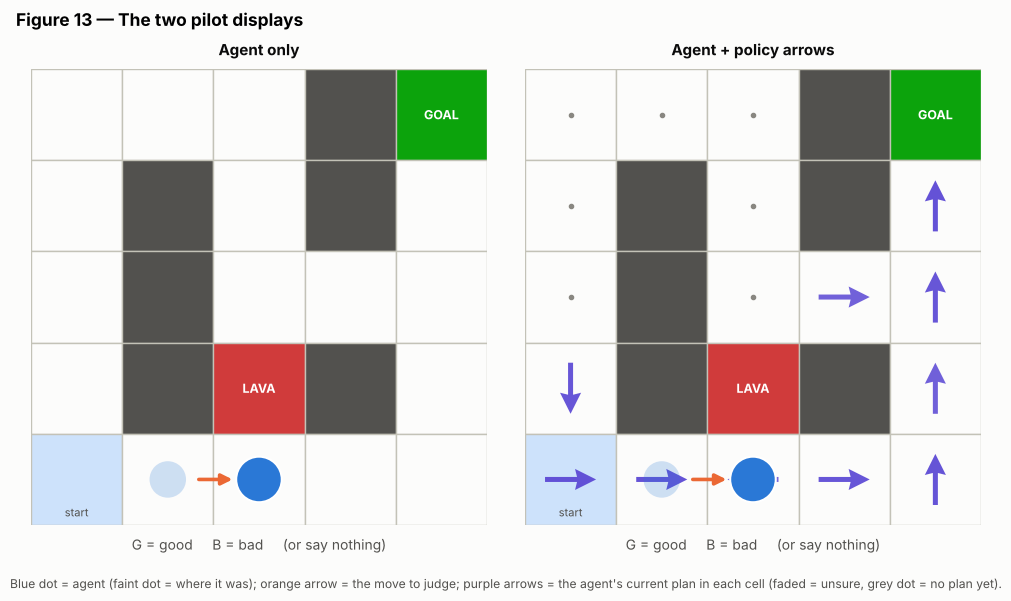

In [25]:
# A mid-session moment: 55 steps into a simulated session (same agent state in both panels).
demo = PilotSession("demo", 1, "explanation", "A", seed=0, max_steps=55)
run_session_headless(demo, SimulatedResponder(demo.oracle, feedback_prob=0.7, error_rate=0.1,
                                              seed=1))
last = demo.rows[-1]
s_prev = last["row"] * demo.env.W + last["col"]
s_now = last["next_row"] * demo.env.W + last["next_col"]
a_last = ACTION_NAMES.index(last["action"])
fig, axes = plt.subplots(1, 2, figsize=(10, 6.0))
for ax, cond in zip(axes, CONDITIONS):
    renderer = GridRenderer(ax, demo.env, show_policy=(cond == "explanation"), oracle=demo.oracle)
    renderer.update(demo.agent.Q, s_prev, a_last, s_now)
    ax.set_title(CONDITION_LABELS[cond], loc="center", pad=10)
    ax.set_xlabel("G = good     B = bad     (or say nothing)", color=INK["secondary"],
                  fontsize=10, labelpad=8)
fig.suptitle("Figure 13 — The two pilot displays", x=0.01, ha="left")
fig.text(0.5, 0.015, "Blue dot = agent (faint dot = where it was); orange arrow = the move to "
         "judge; purple arrows = the agent's current plan in each cell (faded = unsure, grey "
         "dot = no plan yet).", ha="center", fontsize=8.8, color=INK["secondary"], wrap=True)
fig.subplots_adjust(left=0.02, right=0.98, top=0.88, bottom=0.12, wspace=0.06)
save(fig, "fig13_pilot_interface.png")

In [26]:
# ---- from src/hitl_gridworld.py, section [analysis] ----
PILOT_METRICS = [
    ("feedback_to_learn", "Feedback needed", "key presses until the agent learned"),
    ("accuracy", "Feedback that was correct", "share of key presses that were right"),
    ("steps_to_learn_c", "Agent learning speed", "agent steps until learned (fewer = faster)"),
]


def load_pilot(data_dir):
    """Load every session saved by the pilot app in `data_dir`.
    Returns (sessions, steps) DataFrames without practice rounds, or (None, None)."""
    d = Path(data_dir)
    summaries = sorted(d.glob("*_summary.json"))
    if not summaries:
        return None, None
    sessions = pd.DataFrame([json.loads(p.read_text()) for p in summaries])
    sessions = sessions[sessions["condition"].isin(CONDITIONS)].reset_index(drop=True)
    if sessions.empty:
        return None, None
    sessions["aborted"] = sessions["aborted"].astype(bool)
    sessions["steps_to_learn_c"] = sessions["steps_to_learn"].astype(float).fillna(
        sessions["max_steps"].astype(float))
    frames = [pd.read_csv(p) for p in sorted(d.glob("*_steps.csv"))]
    steps = pd.concat(frames, ignore_index=True) if frames else pd.DataFrame()
    if not steps.empty:
        steps = steps[steps["condition"].isin(CONDITIONS)].reset_index(drop=True)
    return sessions, steps


def pilot_table(sessions):
    """One row per participant x condition with the three pre-specified measures."""
    cols = ["participant", "condition", "layout", "session", "learned", "steps_to_learn_c",
            "feedback_to_learn", "correct_to_learn", "accuracy", "feedback_rate",
            "median_rt_ms", "aborted"]
    t = sessions[cols].copy()
    t["condition"] = t["condition"].map(CONDITION_LABELS)
    return t.sort_values(["participant", "session"]).reset_index(drop=True)


def pilot_medians(sessions):
    """Median of each measure per condition (descriptive only)."""
    keep = sessions[~sessions["aborted"]]
    out = keep.groupby("condition")[[m for m, _, _ in PILOT_METRICS] + ["feedback_rate"]].median()
    out.index = [CONDITION_LABELS[c] for c in out.index]
    return out


def plot_pilot_paired(sessions, banner=None):
    """Each participant's value in both conditions (grey line = same person).
    Hollow points mark sessions where the agent had not learned by the step limit."""
    fig, axes = plt.subplots(1, 3, figsize=(11.5, 3.9))
    keep = sessions[~sessions["aborted"]]
    labels = {}
    for ax, (col, title, ylabel) in zip(axes, PILOT_METRICS):
        labels[ax] = []
        for pid, g in keep.groupby("participant"):
            vals = [g.loc[g["condition"] == c, col] for c in CONDITIONS]
            if all(len(v) for v in vals):
                y0, y1 = float(vals[0].iloc[0]), float(vals[1].iloc[0])
                ax.plot([0, 1], [y0, y1], color=INK["axis"], lw=1.3, zorder=1)
                labels[ax].append((1.03, y1, pid))
        if col == "accuracy":
            ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
        for i, c in enumerate(CONDITIONS):
            g = keep[keep["condition"] == c]
            v = g[col].astype(float)
            learned = g["learned"].astype(bool).values
            ax.scatter(np.full(learned.sum(), i), v[learned], s=46, color=CAT[i], zorder=3,
                       edgecolor=INK["surface"], lw=1.5)
            ax.scatter(np.full((~learned).sum(), i), v[~learned], s=46, facecolor="none",
                       edgecolor=CAT[i], lw=1.8, zorder=3)
            if len(v):
                ax.plot([i - 0.2, i + 0.2], [v.median()] * 2, color=INK["primary"], lw=2.2,
                        zorder=4)
        ax.set_xticks([0, 1])
        ax.set_xticklabels([CONDITION_LABELS[c] for c in CONDITIONS])
        ax.set_xlim(-0.45, 1.6)
        ax.set_title(title)
        ax.set_ylabel(ylabel)
        ax.grid(axis="x", visible=False)
    if banner:
        fig.suptitle(banner, color=STATUS["critical"], fontsize=11, x=0.01, ha="left")
    fig.text(0.01, -0.03, "Each point is one session; grey lines join the same person; "
             "black bar = median; hollow = not learned by the step limit.",
             fontsize=8.5, color=INK["secondary"])
    fig.tight_layout()
    for ax, items in labels.items():
        label_ends(ax, items, min_gap=10.0, dx=2.0)
    return fig


def plot_pilot_curves(steps, banner=None):
    """How much of the shortest route the agent has right over the session (1 = learned),
    one small panel per participant."""
    ycol = "route_accuracy" if "route_accuracy" in steps.columns else "policy_accuracy"
    pids = sorted(steps["participant"].unique(), key=lambda p: (participant_number(p), p))
    n = len(pids)
    ncols = min(4, max(1, n))
    nrows = int(np.ceil(n / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(3.1 * ncols, 2.8 * nrows), squeeze=False,
                             sharey=True)
    for k, pid in enumerate(pids):
        ax = axes[k // ncols][k % ncols]
        for i, c in enumerate(CONDITIONS):
            g = steps[(steps["participant"] == pid) & (steps["condition"] == c)]
            if len(g):
                ax.plot(g["step"], g[ycol], color=CAT[i], lw=1.8, label=CONDITION_LABELS[c])
                done = g[g["learned"] == 1]
                if len(done):
                    ax.scatter([done["step"].iloc[0]], [done[ycol].iloc[0]],
                               s=40, color=CAT[i], edgecolor=INK["surface"], zorder=3)
        ax.set_title(pid)
        ax.set_ylim(-0.02, 1.05)
        ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
        ax.set_xlabel("agent step")
        if k % ncols == 0:
            ax.set_ylabel("route cells right\n(dot = learned)" if ycol == "route_accuracy"
                          else "policy accuracy")
    for k in range(n, nrows * ncols):
        axes[k // ncols][k % ncols].set_visible(False)
    handles, labels = axes[0][0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper right", ncol=2, bbox_to_anchor=(1.0, 1.02))
    if banner:
        fig.suptitle(banner, color=STATUS["critical"], fontsize=11, x=0.01, ha="left", y=1.02)
    fig.tight_layout()
    return fig


def canonical_col(layout, col, width=5):
    """Map B is the mirror of map A; express its columns in map-A coordinates."""
    return width - 1 - col if layout == "B" else col


def feedback_error_map(steps):
    """Per condition: for every cell (map-A coordinates) the number of key presses and
    the share that were wrong according to the shortest-path oracle."""
    fb = steps[steps["feedback"] != 0].copy()
    fb["c_col"] = [canonical_col(l, c) for l, c in zip(fb["layout"], fb["col"])]
    fb["wrong"] = 1 - fb["feedback_correct"].astype(int)
    out = {}
    for c in CONDITIONS:
        g = fb[fb["condition"] == c]
        n = np.zeros((5, 5))
        w = np.zeros((5, 5))
        for (r, cc), grp in g.groupby(["row", "c_col"]):
            n[int(r), int(cc)] = len(grp)
            w[int(r), int(cc)] = grp["wrong"].sum()
        out[c] = (n, w)
    return out


def plot_error_map(steps, banner=None):
    """Where were key presses wrong? Shade = share of wrong presses in that cell."""
    maps = feedback_error_map(steps)
    env = GridWorld("A")
    oracle = Oracle(env)
    fig, axes = plt.subplots(1, 2, figsize=(8.6, 4.4))
    cmap = seq_cmap()
    for ax, c in zip(axes, CONDITIONS):
        n, w = maps[c]
        share = np.full(env.n_states, np.nan)
        for s in range(env.n_states):
            r, cc = env.rc(s)
            if n[r, cc] > 0 and env.cell_type[s] == FREE:
                share[s] = w[r, cc] / n[r, cc]
        draw_grid(ax, env, values=share, cmap=cmap, vmin=0.0, vmax=1.0)
        for s in oracle.states:
            r, cc = env.rc(s)
            if n[r, cc] > 0:
                txt_color = "white" if share[s] > 0.55 else INK["primary"]
                ax.text(cc, r, f"{int(w[r, cc])}/{int(n[r, cc])}", ha="center", va="center",
                        fontsize=8.5, color=txt_color, zorder=3)
        ax.set_title(f"{CONDITION_LABELS[c]}")
    sm = plt.cm.ScalarMappable(norm=Normalize(0, 1), cmap=cmap)
    cb = fig.colorbar(sm, ax=list(axes), shrink=0.75, pad=0.02)
    cb.set_label("share of key presses that were wrong", color=INK["secondary"])
    cb.outline.set_visible(False)
    fig.text(0.01, 0.02, "Numbers = wrong / all key presses in that cell (map B is mirrored "
             "onto map A).", fontsize=8.5, color=INK["secondary"])
    if banner:
        fig.suptitle(banner, color=STATUS["critical"], fontsize=11, x=0.01, ha="left")
    return fig


def predict_steps(sweep_df, error_rate, feedback_prob):
    """Simulation-predicted median time-to-learn for a trainer with the given error rate
    and feedback rate: bilinear interpolation of log(median) over the Part 2 sweep."""
    med = (sweep_df.groupby(["feedback_prob", "error_rate"])["steps_to_learn_c"].median()
           .unstack("error_rate"))
    ps = np.array(med.index, dtype=float)
    es = np.array(med.columns, dtype=float)
    z = np.log(med.values)
    e = float(np.clip(error_rate, es.min(), es.max()))
    p = float(np.clip(feedback_prob, ps.min(), ps.max()))
    i = int(np.clip(np.searchsorted(ps, p) - 1, 0, len(ps) - 2))
    j = int(np.clip(np.searchsorted(es, e) - 1, 0, len(es) - 2))
    tp = (p - ps[i]) / (ps[i + 1] - ps[i])
    te = (e - es[j]) / (es[j + 1] - es[j])
    top = z[i, j] * (1 - te) + z[i, j + 1] * te
    bottom = z[i + 1, j] * (1 - te) + z[i + 1, j + 1] * te
    return float(np.exp(top * (1 - tp) + bottom * tp))


def plot_observed_vs_predicted(sessions, sweep_df, banner=None):
    """Does the simulation predict how fast each session's agent learned, given only that
    person's feedback accuracy and feedback rate?"""
    keep = sessions[(~sessions["aborted"]) & sessions["accuracy"].notna()]
    fig, ax = plt.subplots(figsize=(5.2, 4.6))
    lo, hi = np.inf, 0.0
    for i, c in enumerate(CONDITIONS):
        g = keep[keep["condition"] == c]
        pred = [predict_steps(sweep_df, 1 - a, f) for a, f in zip(g["accuracy"], g["feedback_rate"])]
        obs = g["steps_to_learn_c"].astype(float).values
        ax.scatter(pred, obs, s=50, color=CAT[i], edgecolor=INK["surface"], lw=1.5,
                   label=CONDITION_LABELS[c], zorder=3)
        for x, y, pid in zip(pred, obs, g["participant"]):
            ax.annotate(pid, (x, y), xytext=(5, 3), textcoords="offset points", fontsize=8,
                        color=INK["secondary"])
        if len(pred):
            lo, hi = min(lo, min(pred), obs.min()), max(hi, max(pred), obs.max())
    if np.isfinite(lo):
        ax.plot([lo * 0.8, hi * 1.25], [lo * 0.8, hi * 1.25], color=INK["muted"], ls="--",
                lw=1.2)
        ax.annotate("prediction = observation", xy=(hi * 1.25, hi * 1.25), xytext=(0, -12),
                    textcoords="offset points", fontsize=8, color=INK["muted"], ha="right",
                    va="top", rotation=0)
    ax.set_xscale("log")
    ax.set_yscale("log")
    plain = matplotlib.ticker.FuncFormatter(lambda v, _: f"{v:g}")
    for axis in (ax.xaxis, ax.yaxis):
        axis.set_major_formatter(plain)
        axis.set_minor_formatter(matplotlib.ticker.NullFormatter())
    ax.set_xlabel("predicted steps to learn (simulation, Part 2)")
    ax.set_ylabel("observed steps to learn")
    ax.set_title("Observed vs simulated learning speed")
    ax.legend(loc="upper left")
    if banner:
        fig.suptitle(banner, color=STATUS["critical"], fontsize=10.5, x=0.01, ha="left")
    fig.tight_layout()
    return fig


def pilot_markdown(sessions):
    """Markdown block for the README: per-participant table and per-condition medians."""
    t = pilot_table(sessions)
    lines = [f"**Participants:** {sessions['participant'].nunique()} "
             f"(sessions: {len(sessions)}). Descriptive results only - see Limitations.", "",
             "| Participant | Session | Display | Map | Learned | Agent steps to learn "
             "| Key presses until learned | Correct presses | Accuracy | Presses per step |",
             "|---|---|---|---|---|---|---|---|---|---|"]
    for _, r in t.iterrows():
        acc = "-" if pd.isna(r["accuracy"]) else f"{r['accuracy']:.0%}"
        rate = "-" if pd.isna(r["feedback_rate"]) else f"{r['feedback_rate']:.2f}"
        steps_txt = f"{int(r['steps_to_learn_c'])}" + ("" if r["learned"] else "+")
        lines.append(f"| {r['participant']} | {int(r['session'])} | {r['condition']} | "
                     f"{r['layout']} | {'yes' if r['learned'] else 'no'} | {steps_txt} | "
                     f"{int(r['feedback_to_learn'])} | {int(r['correct_to_learn'])} | "
                     f"{acc} | {rate} |")
    med = pilot_medians(sessions)
    lines += ["", "| Median per display | Key presses until learned | Accuracy "
              "| Agent steps to learn | Presses per step |", "|---|---|---|---|---|"]
    for name, r in med.iterrows():
        lines.append(f"| {name} | {r['feedback_to_learn']:.0f} | {r['accuracy']:.0%} | "
                     f"{r['steps_to_learn_c']:.0f} | {r['feedback_rate']:.2f} |")
    lines += ["", "`+` = the agent had not learned by the step limit (value is a lower bound).",
              "", "![Pilot: paired results](figures/pilot_paired.png)",
              "", "![Pilot: learning curves](figures/pilot_curves.png)",
              "", "![Pilot: where feedback was wrong](figures/pilot_error_map.png)"]
    return "\n".join(lines)


def update_readme_block(readme_path, block, start="<!-- PILOT-RESULTS:START -->",
                        end="<!-- PILOT-RESULTS:END -->"):
    """Replace the text between the two markers in the README with `block`."""
    p = Path(readme_path)
    text = p.read_text()
    i, j = text.find(start), text.find(end)
    if i < 0 or j < 0 or j < i:
        raise ValueError("README markers not found")
    p.write_text(text[: i + len(start)] + "\n" + block.strip() + "\n" + text[j:])

### 3a. Pilot analysis (pre-specified)

The cell below loads real logs from `pilot/data/`. **If there are none yet, it creates four simulated participants instead** — with the *same* error rate and feedback rate in both displays, i.e. no true effect — purely to check that logging, loading, tables and figures work end to end. Their figures are saved to `figures/pipeline_check/`, never to the README.

In [27]:
sessions, steps = load_pilot(PILOT_DATA)
REAL_PILOT = sessions is not None
if REAL_PILOT:
    BANNER, PILOT_FIGS = None, FIG
    print(f"Real pilot data: {sessions['participant'].nunique()} participants, "
          f"{len(sessions)} sessions.")
else:
    import shutil
    BANNER, PILOT_FIGS = "PIPELINE CHECK — simulated participants, not human data", FIG / "pipeline_check"
    shutil.rmtree(PIPELINE_CHECK, ignore_errors=True)
    rng = np.random.default_rng(2026)
    for k in range(1, 5):
        pid = f"P{k}"
        fb_prob, err = rng.uniform(0.35, 0.8), rng.uniform(0.05, 0.2)   # same in both displays
        for session_no, condition, layout in counterbalanced_order(pid):
            sess = PilotSession(pid, session_no, condition, layout, seed=100 * k + session_no)
            run_session_headless(sess, SimulatedResponder(sess.oracle, fb_prob, err,
                                                          seed=10 * k + session_no))
            sess.save(PIPELINE_CHECK, extra={"simulated": True})
    sessions, steps = load_pilot(PIPELINE_CHECK)
    print("No real pilot data in pilot/data/ yet -> analysis below runs on 4 SIMULATED "
          "participants (no true effect) to test the pipeline. These are NOT results.")
PILOT_FIGS.mkdir(parents=True, exist_ok=True)
display(pilot_table(sessions))
display(pilot_medians(sessions).round(2))

No real pilot data in pilot/data/ yet -> analysis below runs on 4 SIMULATED participants (no true effect) to test the pipeline. These are NOT results.


,participant,condition,layout,session,learned,steps_to_learn_c,feedback_to_learn,correct_to_learn,accuracy,feedback_rate,median_rt_ms,aborted
0,P1,Agent only,A,1,True,140.0,62,49,0.790323,0.442857,481.90,False
1,P1,Agent + policy arrows,B,2,True,288.0,126,104,0.825397,0.437500,441.95,False
2,P2,Agent + policy arrows,A,1,True,108.0,63,59,0.936508,0.583333,443.30,False
3,P2,Agent only,B,2,True,188.0,114,109,0.956140,0.606383,415.50,False
4,P3,Agent only,A,1,True,258.0,127,106,0.834646,0.492248,442.00,False
5,P3,Agent + policy arrows,B,2,True,83.0,41,32,0.780488,0.493976,425.70,False
6,P4,Agent + policy arrows,A,1,True,46.0,30,28,0.933333,0.652174,416.60,False
7,P4,Agent only,B,2,True,59.0,44,42,0.954545,0.745763,468.45,False


,feedback_to_learn,accuracy,steps_to_learn_c,feedback_rate
Agent only,88.0,0.89,164.0,0.55
Agent + policy arrows,52.0,0.88,95.5,0.54


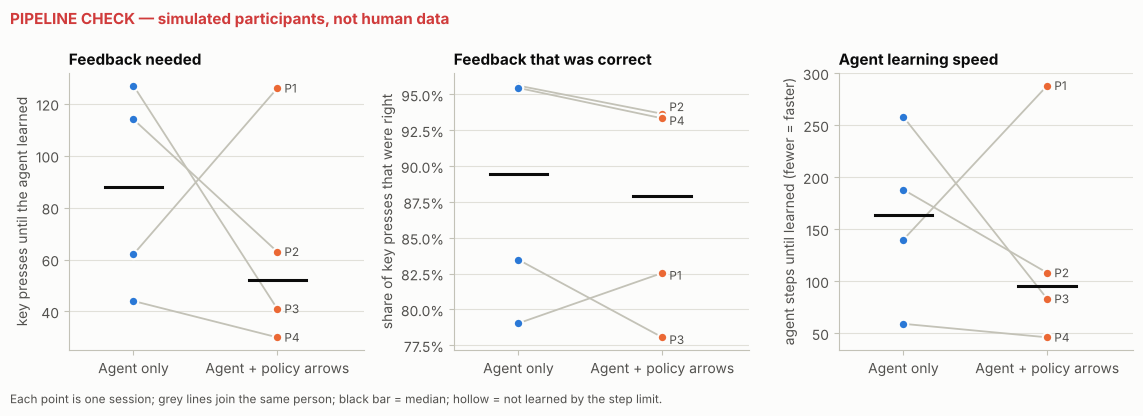

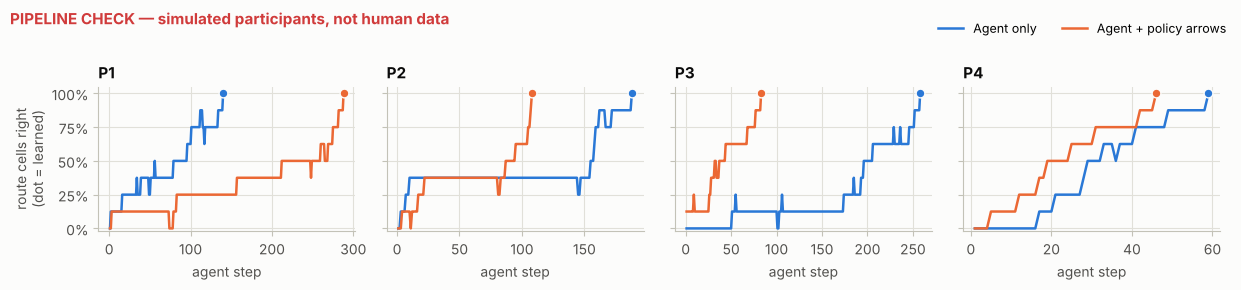

In [28]:
fig = plot_pilot_paired(sessions, banner=BANNER)
save(fig, "pilot_paired.png", folder=PILOT_FIGS)
fig = plot_pilot_curves(steps, banner=BANNER)
save(fig, "pilot_curves.png", folder=PILOT_FIGS)

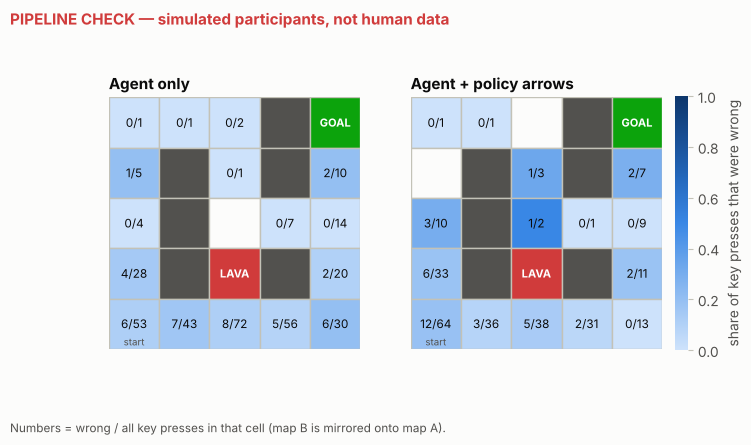

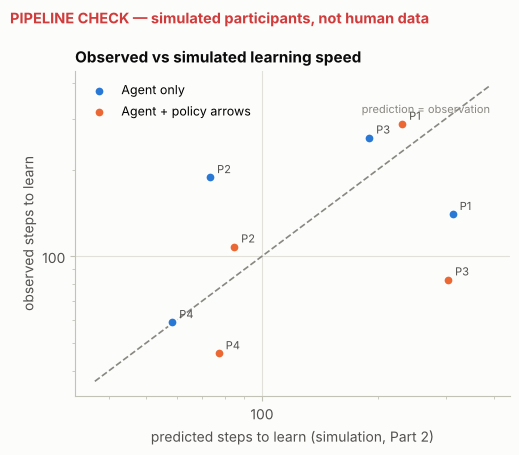

**A lesson from the pipeline check.** These four simulated people have *exactly the same* error rate and feedback rate in both displays, yet the medians still differ: 88 vs 52 key presses and 164 vs 96 agent steps (agent only vs. arrows). That is chance alone. With four real people, differences of this size can also be chance — which is why the pilot is reported descriptively and why Part 4 sizes a real study.

In [29]:
fig = plot_error_map(steps, banner=BANNER)
save(fig, "pilot_error_map.png", folder=PILOT_FIGS)
fig = plot_observed_vs_predicted(sessions, sw, banner=BANNER)
save(fig, "pilot_observed_vs_predicted.png", folder=PILOT_FIGS)
if not REAL_PILOT:
    med_sim = pilot_medians(sessions)
    a_row, e_row = med_sim.loc["Agent only"], med_sim.loc["Agent + policy arrows"]
    display(Markdown(
        "**A lesson from the pipeline check.** These four simulated people have *exactly the "
        "same* error rate and feedback rate in both displays, yet the medians still differ: "
        f"{a_row['feedback_to_learn']:.0f} vs {e_row['feedback_to_learn']:.0f} key presses and "
        f"{a_row['steps_to_learn_c']:.0f} vs {e_row['steps_to_learn_c']:.0f} agent steps "
        "(agent only vs. arrows). That is chance alone. With four real people, differences "
        "of this size can also be chance — which is why the pilot is reported descriptively "
        "and why Part 4 sizes a real study."))

**How to read these once real data exists.** The first figure answers the three questions directly (feedback needed, feedback correct, learning speed) for each person in both displays. The error map shows *where* people misjudge moves — e.g. whether the arrows reduce mistakes on the detour cells. The last figure asks whether Part 2's simulation, given only a person's accuracy and feedback rate, predicts how fast their agent learned; if it does, accuracy and amount of feedback are enough to explain the effect of the display.

## Part 4 — Next step: how many people would a real study need?

A paired test with 4 people cannot reach the usual 5 % significance level: even if all four improve, a sign-flip (permutation) test gives p = 2/16 = 0.125. To plan a real study, we simulate one: each person has their own error rate (about 20 % without explanations, i.e. $C = 0.8$; person-to-person spread 7 points), explanations lower it by Δ, the person trains once in each display (feedback on half the steps), and each session's learning time is drawn from the Part 2 simulations at that error rate. **This rests on assumptions — the pilot's job is to replace them with measured values.**

In [30]:
# ---- from src/hitl_gridworld.py, section [power] ----
def sign_flip_pvalue(d, n_perm=4000, rng=None):
    """Two-sided paired sign-flip (permutation) test of mean(d) = 0.
    Exact enumeration for n <= 12, Monte Carlo otherwise."""
    d = np.asarray(d, dtype=float)
    n = d.size
    if n == 0:
        return float("nan")
    obs = abs(d.mean())
    if n <= 12:
        signs = 1.0 - 2.0 * ((np.arange(2 ** n)[:, None] >> np.arange(n)) & 1)
        null = np.abs((signs * d).mean(axis=1))
        return float(np.mean(null >= obs - 1e-12))
    rng = np.random.default_rng(rng)
    signs = rng.choice((-1.0, 1.0), size=(n_perm, n))
    null = np.abs((signs * d).mean(axis=1))
    return float((1 + np.sum(null >= obs - 1e-12)) / (n_perm + 1))


def power_by_simulation(outcomes, errors, base_error=0.25, deltas=(0.05, 0.10, 0.20),
                        sd_between=0.07, ns=(4, 8, 12, 16, 24, 32), reps=400, alpha=0.05,
                        seed=0):
    """Power of a within-subject study (each person trains once with and once without
    explanations) to detect that explanations lower the feedback error rate by `delta`.

    outcomes[i]  simulated time-to-learn samples for error rate errors[i]
                 (one fixed feedback rate - see the notebook).
    Each simulated person has their own error rate e ~ Normal(base_error, sd_between)
    without explanations and e - delta with them; each of their two sessions is a fresh
    simulated run at the nearest simulated error rate. Test: sign-flip test on the
    per-person difference in log time-to-learn, two-sided, at level alpha."""
    rng = np.random.default_rng(seed)
    errors = np.asarray(errors, dtype=float)
    pools = [np.asarray(o, dtype=float) for o in outcomes]
    power = {}
    for delta in deltas:
        row = []
        for n in ns:
            hits = 0
            for _ in range(reps):
                e0 = np.clip(rng.normal(base_error, sd_between, n), 0.0, errors.max())
                e1 = np.clip(e0 - delta, 0.0, errors.max())
                i0 = np.abs(errors[None, :] - e0[:, None]).argmin(axis=1)
                i1 = np.abs(errors[None, :] - e1[:, None]).argmin(axis=1)
                y0 = np.array([pools[k][rng.integers(len(pools[k]))] for k in i0])
                y1 = np.array([pools[k][rng.integers(len(pools[k]))] for k in i1])
                p = sign_flip_pvalue(np.log(y0) - np.log(y1), n_perm=2000, rng=rng)
                hits += p < alpha
            row.append(hits / reps)
        power[delta] = np.array(row)
    return power

smallest possible two-sided p-value with 4 participants: 0.125


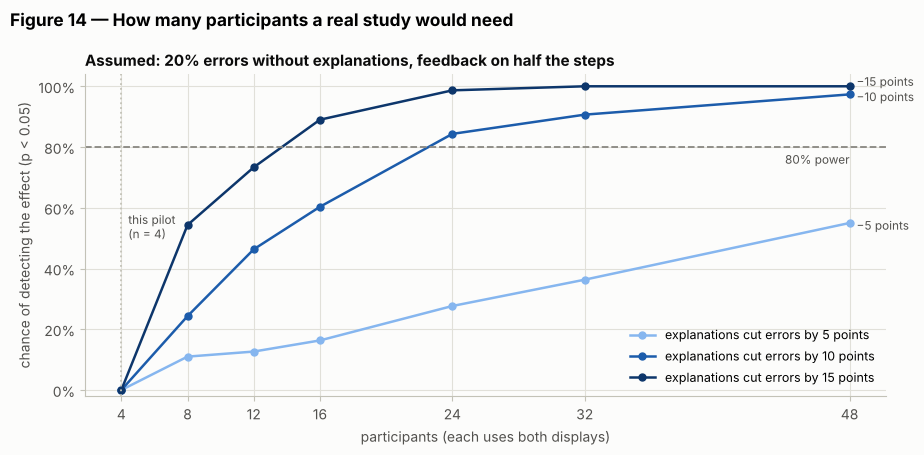

,delta=0.05,delta=0.1,delta=0.15
participants,,,
4,0.00,0.00,0.00
8,0.11,0.24,0.54
12,0.13,0.46,0.73
16,0.16,0.60,0.89
24,0.28,0.84,0.99
32,0.36,0.91,1.00
48,0.55,0.97,1.00


**Participants needed for 80 % power** (under the assumptions above): Δ = 5 points → **> 48**, Δ = 10 points → **24**, Δ = 15 points → **16**

In [31]:
print("smallest possible two-sided p-value with 4 participants:", sign_flip_pvalue([1, 1, 1, 1]))
half = sw[sw["feedback_prob"] == 0.5]
outcomes = [half.loc[np.isclose(half["error_rate"], e), "steps_to_learn_c"].values for e in ERRORS]
NS = [4, 8, 12, 16, 24, 32, 48]
DELTAS = (0.05, 0.10, 0.15)
power = power_by_simulation(outcomes, ERRORS, base_error=0.20, deltas=DELTAS, sd_between=0.07,
                            ns=NS, reps=60 if FAST else 300, seed=1)
power_df = pd.DataFrame({f"delta={d}": power[d] for d in DELTAS}, index=NS)
power_df.index.name = "participants"
power_df.to_csv(RES / "part4_power.csv")

fig, ax = plt.subplots(figsize=(9, 4.6))
ends = []
for k, d in zip((0, 2, 3), DELTAS):
    ax.plot(NS, power[d], marker="o", ms=5, color=RAMP4[k],
            label=f"explanations cut errors by {d * 100:.0f} points")
    ends.append((NS[-1], power[d][-1], f"−{d * 100:.0f} points"))
ax.axhline(0.8, color=INK["muted"], ls="--", lw=1.3)
ax.annotate("80% power", xy=(NS[-1], 0.8), xytext=(0, -12), textcoords="offset points",
            ha="right", fontsize=8.5, color=INK["secondary"])
ax.axvline(4, color=INK["axis"], ls=":", lw=1.3)
ax.annotate("this pilot\n(n = 4)", xy=(4, 0.5), xytext=(5, 0), textcoords="offset points",
            fontsize=8.5, color=INK["secondary"])
ax.set_xticks(NS)
ax.set_ylim(-0.02, 1.04)
ax.yaxis.set_major_formatter(matplotlib.ticker.PercentFormatter(1.0))
ax.set_xlabel("participants (each uses both displays)")
ax.set_ylabel("chance of detecting the effect (p < 0.05)")
ax.legend(loc="lower right")
ax.set_title("Assumed: 20% errors without explanations, feedback on half the steps")
fig.suptitle("Figure 14 — How many participants a real study would need", x=0.01, ha="left")
fig.tight_layout()
label_ends(ax, ends)
save(fig, "fig14_power_analysis.png")


def n_needed(curve):
    hit = [n for n, pw in zip(NS, curve) if pw >= 0.8]
    return f"{hit[0]}" if hit else f"> {NS[-1]}"


display(power_df.round(2))
display(Markdown("**Participants needed for 80 % power** (under the assumptions above): " +
                 ", ".join(f"Δ = {d * 100:.0f} points → **{n_needed(power[d])}**" for d in DELTAS)))
KEY.update({f"n_for_80pct_power_delta_{d}": n_needed(power[d]) for d in DELTAS})

## Animation — watching the plan form

One simulated session in the explanation display (feedback on 60 % of steps, 10 % wrong). The purple arrows are the explanation a participant would see; GOOD/BAD shows the feedback given on each move.

122 steps; learned at step 122; GIF size 227 kB


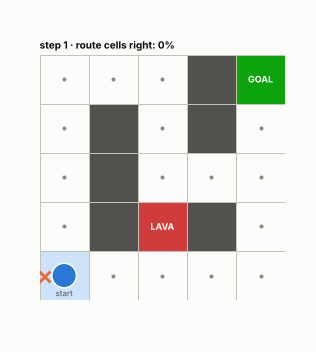

In [32]:
from matplotlib.animation import FuncAnimation, PillowWriter

anim = PilotSession("anim", 1, "explanation", "A", seed=11, max_steps=300)
responder = SimulatedResponder(anim.oracle, feedback_prob=0.6, error_rate=0.1, seed=5)
frames, clock = [], 0.0
anim.start(now=clock)
while not anim.finished:
    p = anim.pending
    h, rt = responder.respond(p)
    if h and rt < 800:
        anim.give_feedback(h, now=clock + rt / 1000)
    else:
        h = 0
    frames.append((anim.agent.Q.copy(), p["s"], p["a"], p["s2"], p["step"], h))
    clock += 0.8
    anim.advance(now=clock)
keep = frames[::2] + [frames[-1]] * 8          # every 2nd step, then hold the last frame
fig, ax = plt.subplots(figsize=(4.4, 4.9), dpi=72)
renderer = GridRenderer(ax, anim.env, show_policy=True, oracle=anim.oracle)
title = ax.set_title("", loc="left", fontsize=10)
fb_text = ax.text(4.45, -0.6, "", ha="right", va="bottom", fontsize=11, weight="bold")


def draw_frame(i):
    Q, s, a, s2, step, h = keep[i]
    renderer.update(Q, s, a, s2)
    done = anim.learned_at is not None and step >= anim.learned_at
    title.set_text(f"step {step} · " + ("route learned" if done else
                   f"route cells right: {route_accuracy(Q, anim.oracle):.0%}"))
    fb_text.set_text({1: "GOOD", -1: "BAD", 0: ""}[h])
    fb_text.set_color(STATUS["good_text"] if h > 0 else STATUS["critical"])
    return []


animation = FuncAnimation(fig, draw_frame, frames=len(keep), interval=140, blit=False)
animation.save(FIG / "policy_learning.gif", writer=PillowWriter(fps=7), dpi=72)
plt.close(fig)
print(f"{len(frames)} steps; learned at step {anim.learned_at}; "
      f"GIF size {(FIG / 'policy_learning.gif').stat().st_size / 1e3:.0f} kB")
display(Image(filename=str(FIG / "policy_learning.gif")))

In [33]:
(RES / "key_numbers.json").write_text(json.dumps(KEY, indent=2))
print(json.dumps(KEY, indent=2))
print(f"Notebook finished in {(time.time() - T_START) / 60:.1f} minutes.")

{
  "no_trainer_median_steps": 430.5,
  "perfect_every_step": 31.5,
  "err10_every_step": 72.0,
  "err30_every_step": 494.0,
  "err50_every_step_learned_share": 0.08,
  "perfect_half": 66.5,
  "err10_half": 115.0,
  "err30_half": 451.5,
  "speedup_err30_half_alpha0.1": 4.20045045045045,
  "speedup_err30_half_alpha0.5": 1.0798004987531171,
  "n_for_80pct_power_delta_0.05": "> 48",
  "n_for_80pct_power_delta_0.1": "24",
  "n_for_80pct_power_delta_0.15": "16"
}
Notebook finished in 1.0 minutes.


## Summary, limitations and next steps

**What this first test shows.** (1) The Q-learning implementation reproduces Sutton & Barto's Cliff Walking result and learns the 5×5 task from reward alone. (2) Good/bad feedback can make it learn many times faster — but only if the feedback is mostly right: the speed-up shrinks quickly as errors rise and is gone at around 30 % wrong feedback for this learner (Part 2). (3) So if an explanation makes people's feedback even 10 points more accurate, the simulation predicts a large change in learning speed — which is what the human pilot is built to probe.

**Limitations.**
* **The human pilot is tiny** (3–4 friends, not naive users) and, at the time of writing, still to be run; with n = 4 no difference can be statistically significant (Part 4). Results will be descriptive only.
* **One toy task.** A 5×5 deterministic gridworld; people can see the whole map, which makes judging moves easier than in most real tasks.
* **"Correct" is defined by a shortest-path oracle.** A person may reasonably judge a move differently (e.g. a safe detour), which the oracle counts as wrong.
* **One simple learner.** Feedback is used as shaping reward with a fixed weight; how harmful errors are depends strongly on the learner (Figure 12). Learners built for noisy or silent feedback (Advise, SABL, COACH) might change the picture.
* **The simulated trainer is simplistic.** Its errors are independent and its silence random. Real people taper their feedback over time, use silence strategically (Loftin et al., 2016) and judge relative to the agent's current behaviour (MacGlashan et al., 2017).
* **Order and learning effects.** Each person uses both displays; counterbalancing and a mirrored map reduce, but do not remove, practice effects. Key presses are credited to the move on screen, so very late presses can be misattributed.
* **The explanation is one specific display** (greedy-policy arrows with a confidence fade); other explanations (Q-value maps, policy summaries such as HIGHLIGHTS) may act differently — and showing uncertainty can also distract trainers (Li et al., 2015).

**Next steps.** Run the pilot (≈ 15 minutes per person); use it to estimate real error and feedback rates and their spread; update the power analysis with those numbers and pre-register a study of about the size it indicates; compare a learner that models feedback noise (e.g. Advise) with plain reward shaping; and test richer explanations in a larger domain where the person cannot see everything at once.

## References

* Amir, D., & Amir, O. (2018). HIGHLIGHTS: Summarizing agent behavior to people. *AAMAS*, 1168–1176.
* Griffith, S., Subramanian, K., Scholz, J., Isbell, C. L., & Thomaz, A. L. (2013). Policy shaping: Integrating human feedback with reinforcement learning. *NeurIPS*, 2625–2633.
* Knox, W. B., & Stone, P. (2009). Interactively shaping agents via human reinforcement: The TAMER framework. *K-CAP*.
* Knox, W. B., & Stone, P. (2010). Combining manual feedback with subsequent MDP reward signals for reinforcement learning. *AAMAS*.
* Lee, K., Smith, L., Dragan, A., & Abbeel, P. (2021). B-Pref: Benchmarking preference-based reinforcement learning. *NeurIPS Datasets and Benchmarks*.
* Li, G., Hung, H., Whiteson, S., & Knox, W. B. (2013). Using informative behavior to increase engagement in the TAMER framework. *AAMAS*. Extended version: Li, Whiteson, Knox & Hung (2015), *Autonomous Agents and Multi-Agent Systems*, doi:10.1007/s10458-015-9308-2.
* Loftin, R., Peng, B., MacGlashan, J., Littman, M. L., Taylor, M. E., Huang, J., & Roberts, D. L. (2016). Learning behaviors via human-delivered discrete feedback: Modeling implicit feedback strategies to speed up learning. *Autonomous Agents and Multi-Agent Systems*, 30(1), 30–59.
* MacGlashan, J., Ho, M. K., Loftin, R., Peng, B., Wang, G., Roberts, D. L., Taylor, M. E., & Littman, M. L. (2017). Interactive learning from policy-dependent human feedback. *ICML*, PMLR 70, 2285–2294.
* Peng, B., MacGlashan, J., Loftin, R., Littman, M. L., Roberts, D. L., & Taylor, M. E. (2016). A need for speed: Adapting agent action speed to improve task learning from non-expert humans. *AAMAS*, 957–965.
* Retzlaff, C. O., Das, S., Wayllace, C., Mousavi, P., Afshari, M., Yang, T., Saranti, A., Angerschmid, A., Taylor, M. E., & Holzinger, A. (2024). Human-in-the-loop reinforcement learning: A survey and position on requirements, challenges, and opportunities. *JAIR*, 79, 359–415.
* Sutton, R. S., & Barto, A. G. (2018). *Reinforcement Learning: An Introduction* (2nd ed.), Ch. 6. MIT Press.
* Teso, S., & Kersting, K. (2019). Explanatory interactive machine learning. *AIES*, 239–245.
* Thomaz, A. L., & Breazeal, C. (2008). Teachable robots: Understanding human teaching behavior to build more effective robot learners. *Artificial Intelligence*, 172(6–7), 716–737.